# 03 · Clustering y validación

Este notebook aplica los algoritmos de clustering acordados sobre los dos universos preparados en el notebook anterior de selección de variables y preprocesamiento:

- **Universo general**: municipios españoles sin utilizar las variables de alquiler de baja cobertura.
- **Universo específico**: municipios por encima del umbral poblacional definido en el EDA, incorporando las variables de alquiler que superaron los controles de calidad.

Se comparan cuatro familias de métodos con supuestos diferentes:

1. **K-Means**: partición por centroides, altamente interpretable.
2. **Ward (clustering jerárquico aglomerativo)**: contraste jerárquico que minimiza la varianza intracluster.
3. **Gaussian Mixture Model (GMM)**: clustering probabilístico con grupos elípticos y distinta dispersión.
4. **HDBSCAN**: análisis complementario basado en densidad, capaz de identificar ruido y clusters con densidades diferentes.

Para la selección final del algoritmo usaremos distintas métricas para evaluar los clusters, además de analizar el tamaño de cada grupo y la estabilidad por remuestreo. Más adelante, en el siguiente notebook interpretaremos los distintos grupos obtenidos para los dos universos considerados.

Importamos las librerías necesarias.

In [27]:
import boto3
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import redshift_connector
import pickle
from io import BytesIO
import warnings
import tempfile
from itertools import combinations

from IPython.display import display
from joblib import Memory
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (
    adjusted_mutual_info_score,
    adjusted_rand_score,
    calinski_harabasz_score,
    davies_bouldin_score,
    silhouette_score,
)

try:
    from sklearn.cluster import HDBSCAN
    HDBSCAN_BACKEND = 'sklearn'
except ImportError:
    try:
        import hdbscan as _hdbscan
        HDBSCAN = _hdbscan.HDBSCAN
        HDBSCAN_BACKEND = 'hdbscan'
    except ImportError:
        HDBSCAN = None
        HDBSCAN_BACKEND = None

pd.set_option('display.max_columns', 180)
pd.set_option('display.max_rows', 180)

Nos conectamos a Redshift para importar los datos de la capa 'curated'.

In [28]:
host = "redshift-tfm-curated.159012148774.eu-west-3.redshift-serverless.amazonaws.com"
database = "redshift-tfm-curated"
user = "tfm_admin"
password = "ldq!Zl>e>7CXzAkZa8Y+jU!_3j$4G8N>3%+>_JAH3m`)<)"
port = 5439

conn = redshift_connector.connect(
    host=host,
    database=database,
    user=user,
    password=password,
    port=port
)

QUERY = f"""
SELECT *
FROM curated.municipios
ORDER BY codigo_ine
"""

with conn.cursor() as cursor:
    cursor.execute(QUERY)
    df = cursor.fetch_dataframe()

print(f'Filas: {len(df):,} | Columnas: {df.shape[1]:,}')
display(df.head())

Filas: 8,132 | Columnas: 107


,codigo_ine,municipio,provincia,capital,poblacion_ign,superficie_km2,densidad_poblacion_hab_km2,longitud,latitud,codigo_comunidad,codigo_provincia,inmuebles_urbanos,valor_catastral_total_eur,valor_catastral_suelo_eur,superficie_urbana_m2,parcelas_urbanas,inmuebles_residenciales,valor_catastral_residencial_eur,valor_catastral_suelo_eur_m2,valor_catastral_residencial_medio_eur,edad_media_2025,porcentaje_poblacion_menor_18,porcentaje_poblacion_65_mas,diferencia_edad_media_1_anio,diferencia_edad_media_3_anios,saldo_total,saldo_interior,saldo_exterior,poblacion_2025,variacion_poblacion_1_anio,variacion_poblacion_3_anios,variacion_poblacion_5_anios,renta_neta_media_persona_eur,renta_neta_media_hogar_eur,tamanio_medio_hogar,viviendas_totales,viviendas_vacias,viviendas_uso_esporadico,porcentaje_viviendas_vacias,porcentaje_viviendas_uso_esporadico,viviendas_turisticas,plazas,plazas_por_vivienda,total_infracciones,distancia_costa_km,alquiler_precio_colectiva_mediana,alquiler_precio_colectiva_rango_intercuartilico,alquiler_precio_unifamiliar_mediana,alquiler_precio_unifamiliar_rango_intercuartilico,alquiler_superficie_colectiva_mediana,alquiler_superficie_colectiva_rango_intercuartilico,alquiler_superficie_unifamiliar_mediana,alquiler_superficie_unifamiliar_rango_intercuartilico,alquiler_colectiva_aproximado_eur_m2,alquiler_unifamiliar_aproximado_eur_m2,variacion_alquiler_precio_colectiva_mediana_1_anio,variacion_alquiler_precio_unifamiliar_mediana_1_anio,variacion_alquiler_colectiva_aproximado_eur_m2_1_anio,variacion_alquiler_unifamiliar_aproximado_eur_m2_1_anio,diferencia_alquiler_precio_colectiva_rango_intercuartilico_1_anio,diferencia_alquiler_precio_unifamiliar_rango_intercuartilico_1_anio,diferencia_alquiler_superficie_colectiva_mediana_1_anio,diferencia_alquiler_superficie_colectiva_rango_intercuartilico_1_anio,diferencia_alquiler_superficie_unifamiliar_mediana_1_anio,diferencia_alquiler_superficie_unifamiliar_rango_intercuartilico_1_anio,variacion_alquiler_precio_colectiva_mediana_3_anios,variacion_alquiler_precio_unifamiliar_mediana_3_anios,variacion_alquiler_colectiva_aproximado_eur_m2_3_anios,variacion_alquiler_unifamiliar_aproximado_eur_m2_3_anios,diferencia_alquiler_precio_colectiva_rango_intercuartilico_3_anios,diferencia_alquiler_precio_unifamiliar_rango_intercuartilico_3_anios,diferencia_alquiler_superficie_colectiva_mediana_3_anios,diferencia_alquiler_superficie_colectiva_rango_intercuartilico_3_anios,diferencia_alquiler_superficie_unifamiliar_mediana_3_anios,diferencia_alquiler_superficie_unifamiliar_rango_intercuartilico_3_anios,transacciones_2025,transacciones_nuevas_2025,transacciones_segunda_mano_2025,paro_medio_2025,saldo_interior_por_1000_habitantes,saldo_exterior_por_1000_habitantes,viviendas_turisticas_por_1000_habitantes,paro_por_1000_habitantes,esfuerzo_alquiler_colectiva_pct,esfuerzo_alquiler_unifamiliar_pct,porcentaje_superficie_urbana,diferencia_porcentaje_superficie_urbana_5_anios,variacion_inmuebles_residenciales_5_anios,variacion_valor_catastral_residencial_medio_eur_5_anios,variacion_valor_catastral_suelo_eur_m2_5_anios,inmuebles_residenciales_por_1000_habitantes,diferencia_inmuebles_residenciales_5_anios_por_1000_habitantes,porcentaje_viviendas_turisticas_sobre_inmuebles_residenciales,transacciones_por_1000_inmuebles_residenciales,transacciones_nuevas_por_1000_inmuebles_residenciales,transacciones_segunda_mano_por_1000_inmuebles_residenciales,diferencia_transacciones_1_anio_por_1000_inmuebles_residenciales,diferencia_transacciones_3_anios_por_1000_inmuebles_residenciales,diferencia_transacciones_5_anios_por_1000_inmuebles_residenciales,diferencia_transacciones_nuevas_1_anio_por_1000_inmuebles_residenciales,diferencia_transacciones_nuevas_3_anios_por_1000_inmuebles_residenciales,diferencia_transacciones_nuevas_5_anios_por_1000_inmuebles_residenciales,diferencia_transacciones_segunda_mano_1_anio_por_1000_inmuebles_residenciales,diferencia_transacciones_segunda_mano_3_anios_por_1000_inmuebles_residenciale

## Cargamos los preprocessors y PCA del notebook anterior de selección de variables

Esto garantiza que este notebook utilice exactamente las features, imputaciones, límites de outliers, transformaciones y escalado ya decididos en el anterior.

In [29]:
BUCKET = "s3-tfm-athena-results-159012148774-eu-west-3"

s3_client = boto3.client("s3", region_name="eu-west-3")


def load_pickle_s3(key: str):
    print(f"Cargando → s3://{BUCKET}/{key}")

    obj = s3_client.get_object(
        Bucket=BUCKET,
        Key=key
    )

    return pickle.loads(obj["Body"].read())


# PREPROCESSORS

preprocessor_general = load_pickle_s3(
    "clustering/general/artifacts/preprocessor.pkl"
)

preprocessor_specific = load_pickle_s3(
    "clustering/specific/artifacts/preprocessor.pkl"
)

# COMPROBACIÓN

print(
    f"\nFeatures guardadas en preprocessor general: "
    f"{len(preprocessor_general['features'])}"
)

print(
    f"Features guardadas en preprocessor específico: "
    f"{len(preprocessor_specific['features'])}"
)

print(
    f"Umbral población específico: "
    f"{preprocessor_specific['min_population']:,}"
)

Cargando → s3://s3-tfm-athena-results-159012148774-eu-west-3/clustering/general/artifacts/preprocessor.pkl
Cargando → s3://s3-tfm-athena-results-159012148774-eu-west-3/clustering/specific/artifacts/preprocessor.pkl

Features guardadas en preprocessor general: 29
Features guardadas en preprocessor específico: 50
Umbral población específico: 5,000


In [30]:
def load_pickle_s3(universe: str, filename: str):
    key = f"clustering/{universe}/artifacts/{filename}"

    response = s3_client.get_object(
        Bucket=BUCKET,
        Key=key
    )

    return pickle.loads(
        response['Body'].read()
    )


pca_general = load_pickle_s3(
    'general',
    'pca.pkl'
)

pca_specific = load_pickle_s3(
    'specific',
    'pca.pkl'
)

print('PCA general cargado:', pca_general.n_components_)
print('PCA específico cargado:', pca_specific.n_components_)

PCA general cargado: 17
PCA específico cargado: 23


## Se reconstruye `X_scaled` y `X_pca` del notebook anterior

No se ajusta ningún transformador de nuevo. Se aplica `transform` con los objetos entrenados en el notebook anterior.

In [31]:
def apply_saved_preprocessor(data: pd.DataFrame, prep: dict) -> pd.DataFrame:

    # Variables finales que entrarán al clustering
    features = list(prep['features'])

    # Variables con las que se entrenó el imputador, incluyendo 'poblacion_2025'
    imputer_features = list(prep['imputer'].feature_names_in_)

    # Comprobar que están disponibles en el dataframe
    missing = [c for c in imputer_features if c not in data.columns]
    if missing:
        raise KeyError(
            f'Faltan columnas necesarias para la imputación: {missing}'
        )

    # Datos para el imputador
    X_imp_input = (
        data[imputer_features]
        .apply(pd.to_numeric, errors='coerce')
        .replace([np.inf, -np.inf], np.nan)
    )

    # Imputación
    X_imp = pd.DataFrame(
        prep['imputer'].transform(X_imp_input),
        index=X_imp_input.index,
        columns=imputer_features,
    )

    # Eliminar variables auxiliares
    X_proc = X_imp[features].copy()

    # Winsorización
    for c, bounds in prep.get('winsor_bounds', {}).items():
        if c in X_proc.columns:
            lower, upper = bounds
            X_proc[c] = X_proc[c].clip(
                lower=lower,
                upper=upper
            )

    # Transformaciones logarítmicas ya decididas
    for c in prep.get('log_features', []):
        if c in X_proc.columns:
            X_proc[c] = np.log1p(X_proc[c])

    # Scaler
    scaler_features = list(prep['scaler'].feature_names_in_)

    missing_scaler = [
        c for c in scaler_features
        if c not in X_proc.columns
    ]

    if missing_scaler:
        raise KeyError(
            f'Faltan columnas esperadas por el scaler: {missing_scaler}'
        )

    X_proc = X_proc[scaler_features]

    values = prep['scaler'].transform(X_proc)

    X_scaled = pd.DataFrame(
        values,
        index=X_proc.index,
        columns=scaler_features
    )

    if not np.isfinite(X_scaled.to_numpy()).all():
        raise ValueError(
            'La matriz escalada contiene NaN o infinitos.'
        )

    return X_scaled


# UNIVERSO GENERAL (se excluye País Vasco y Navarra)

PROVINCIAS_EXCLUIDAS = preprocessor_general['excluded_provinces']

df_general = df.loc[
    ~df['provincia'].isin(PROVINCIAS_EXCLUIDAS)
].copy()

X_general_scaled = apply_saved_preprocessor(
    df_general,
    preprocessor_general
)


# UNIVERSO ESPECÍFICO (se excluye también País Vasco y Navarra)

min_population_specific = int(
    preprocessor_specific['min_population']
)

df_specific = df_general.loc[
    pd.to_numeric(
        df_general['poblacion_2025'],
        errors='coerce'
    ) >= min_population_specific
].copy()

X_specific_scaled = apply_saved_preprocessor(
    df_specific,
    preprocessor_specific
)


# PCA

def transform_pca(
    X_scaled: pd.DataFrame,
    pca
) -> pd.DataFrame:

    if X_scaled.shape[1] != pca.n_features_in_:
        raise ValueError(
            f'PCA esperaba {pca.n_features_in_} variables, '
            f'pero recibe {X_scaled.shape[1]}.'
        )

    values = pca.transform(X_scaled)

    return pd.DataFrame(
        values,
        index=X_scaled.index,
        columns=[
            f'PC{i}'
            for i in range(1, values.shape[1] + 1)
        ],
    )


X_general_pca = transform_pca(
    X_general_scaled,
    pca_general
)

X_specific_pca = transform_pca(
    X_specific_scaled,
    pca_specific
)


# Comprobaciones

print('General:')
print(
    '  municipios:', len(df_general),
    '| scaled:', X_general_scaled.shape,
    '| PCA:', X_general_pca.shape
)

print('Específico:')
print(
    '  municipios:', len(df_specific),
    '| scaled:', X_specific_scaled.shape,
    '| PCA:', X_specific_pca.shape
)

print(
    f'\nUmbral población específico: '
    f'{min_population_specific:,}'
)

print(
    '\nPoblación usada como auxiliar en imputación general:',
    'poblacion_2025' in preprocessor_general['imputer'].feature_names_in_
)

print(
    'Población incluida finalmente en clustering general:',
    'poblacion_2025' in X_general_scaled.columns
)

General:
  municipios: 7608 | scaled: (7608, 29) | PCA: (7608, 17)
Específico:
  municipios: 1231 | scaled: (1231, 50) | PCA: (1231, 23)

Umbral población específico: 5,000

Población usada como auxiliar en imputación general: True
Población incluida finalmente en clustering general: False


## Comprobaciones de reproducibilidad

Vamos a comprobar que hemos reproducido adecuadamente todas las transformaciones.

In [32]:
def reproducibility_check(X_scaled, prep, universe):
    expected_n = getattr(prep['scaler'], 'n_samples_seen_', None)
    if isinstance(expected_n, np.ndarray):
        expected_n = int(np.max(expected_n))
    elif expected_n is not None:
        expected_n = int(expected_n)

    row = {
        'universo': universe,
        'n_actual': len(X_scaled),
        'n_preprocessor': expected_n,
        'max_abs_media_scaled': float(X_scaled.mean().abs().max()),
        'max_desviacion_std_1': float((X_scaled.std(ddof=0) - 1).abs().max()),
        'finito': bool(np.isfinite(X_scaled.to_numpy()).all()),
    }
    return row


reproducibility = pd.DataFrame([
    reproducibility_check(X_general_scaled, preprocessor_general, 'general'),
    reproducibility_check(X_specific_scaled, preprocessor_specific, 'specific'),
])
display(reproducibility)

for _, row in reproducibility.iterrows():
    if row['n_preprocessor'] is not None and row['n_actual'] != row['n_preprocessor']:
        warnings.warn(
            f"{row['universo']}: Redshift contiene un número de filas distinto al usado en notebook 02. "
            'El clustering se está aplicando con el preprocesador anterior sobre el snapshot actual.'
        )

,universo,n_actual,n_preprocessor,max_abs_media_scaled,max_desviacion_std_1,finito
0,general,7608,7608,2.618772e-15,2.220446e-16,True
1,specific,1231,1231,4.300198e-15,2.220446e-16,True


## Matrices de trabajo y metadatos

In [33]:
DATASETS = {
    'general': {
        'scaled': X_general_scaled,
        'pca': X_general_pca,
    },
    'specific': {
        'scaled': X_specific_scaled,
        'pca': X_specific_pca,
    },
}

metadata_cols = [c for c in [
    'codigo_ine', 'municipio', 'provincia', 'capital',
    'poblacion_2025', 'longitud', 'latitud'
] if c in df.columns]

META = {
    'general': df_general.loc[X_general_scaled.index, metadata_cols].copy(),
    'specific': df_specific.loc[X_specific_scaled.index, metadata_cols].copy(),
}

matrix_summary = []
for universe, spaces in DATASETS.items():
    for space, X in spaces.items():
        matrix_summary.append({
            'universo': universe,
            'espacio': space,
            'n_municipios': len(X),
            'n_dimensiones': X.shape[1],
        })

matrix_summary = pd.DataFrame(matrix_summary)
display(matrix_summary)

,universo,espacio,n_municipios,n_dimensiones
0,general,scaled,7608,29
1,general,pca,7608,17
2,specific,scaled,1231,50
3,specific,pca,1231,23


# Métricas de evaluación

Utilizaremos las siguientes métricas de evaluación del clustering:

- **Silhouette**: mayor es "mejor"; combina cohesión interna y separación externa.
- **Calinski-Harabasz**: mayor es "mejor".
- **Davies-Bouldin**: menor es "mejor".
- **Entropía normalizada de tamaños**: describe el equilibrio relativo, pero no se usa como objetivo; los mercados reales no tienen por qué ser igual de grandes.
- **Tamaño mínimo/máximo de cluster**: permite detectar soluciones degeneradas.

Para controlar coste y memoria, el silhouette se estima sobre una muestra reproducible cuando el universo supera `SILHOUETTE_SAMPLE_SIZE` observaciones. Las otras métricas utilizan todas las observaciones válidas.

In [34]:
SILHOUETTE_SAMPLE_SIZE = 4_000

def _silhouette_reproducible(X, labels, sample_size=SILHOUETTE_SAMPLE_SIZE):
    n = len(labels)
    if n <= sample_size:
        return float(silhouette_score(X, labels, metric='euclidean'))
    return float(silhouette_score(
        X,
        labels,
        metric='euclidean',
        sample_size=sample_size,
        random_state=RANDOM_STATE,
    ))


def cluster_quality_metrics(X: pd.DataFrame, labels, noise_label=-1) -> dict:
    labels = np.asarray(labels)
    noise_mask = labels == noise_label
    valid_mask = ~noise_mask
    labels_valid = labels[valid_mask]
    X_valid = X.iloc[np.where(valid_mask)[0]]

    unique = np.unique(labels_valid)
    n_clusters = len(unique)
    n_total = len(labels)
    n_clustered = int(valid_mask.sum())

    result = {
        'n_clusters': int(n_clusters),
        'noise_pct': float(noise_mask.mean() * 100),
        'clustered_pct': float(valid_mask.mean() * 100),
        'silhouette': np.nan,
        'calinski_harabasz': np.nan,
        'davies_bouldin': np.nan,
        'min_cluster_n': np.nan,
        'max_cluster_n': np.nan,
        'min_cluster_pct': np.nan,
        'max_cluster_pct': np.nan,
        'size_entropy_norm': np.nan,
    }

    if n_clusters < 2 or n_clustered <= n_clusters:
        return result

    counts = pd.Series(labels_valid).value_counts().sort_index()
    p = counts.to_numpy(dtype=float) / counts.sum()
    entropy = -np.sum(p * np.log(p))
    entropy_norm = entropy / np.log(n_clusters) if n_clusters > 1 else 0.0

    result.update({
        'silhouette': _silhouette_reproducible(X_valid, labels_valid),
        'calinski_harabasz': float(calinski_harabasz_score(X_valid, labels_valid)),
        'davies_bouldin': float(davies_bouldin_score(X_valid, labels_valid)),
        'min_cluster_n': int(counts.min()),
        'max_cluster_n': int(counts.max()),
        'min_cluster_pct': float(counts.min() / n_total * 100),
        'max_cluster_pct': float(counts.max() / n_total * 100),
        'size_entropy_norm': float(entropy_norm),
    })
    return result


def add_warning_flags(results: pd.DataFrame) -> pd.DataFrame:
    out = results.copy()
    out['tiny_cluster_warning'] = out['min_cluster_pct'] < TINY_CLUSTER_WARNING_PCT
    out['high_noise_warning'] = out['noise_pct'] > HIGH_NOISE_WARNING_PCT
    return out

# K-Means

In [35]:
RANDOM_STATE = 42
K_VALUES = list(range(2, 11))  # se probará para k= 2,...,10
KMEANS_N_INIT = 50  # n_init 50
KMEANS_MAX_ITER = 500  # máximo iteraciones 500

# Las siguientes variables servirán a modo de advertencia
TINY_CLUSTER_WARNING_PCT = 1.0
HIGH_NOISE_WARNING_PCT = 30.0

def evaluate_kmeans(universe: str, space: str, X: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for k in K_VALUES:
        model = KMeans(
            n_clusters=k,
            init='k-means++',
            n_init=KMEANS_N_INIT,
            max_iter=KMEANS_MAX_ITER,
            random_state=RANDOM_STATE,
        )
        labels = model.fit_predict(X)
        metrics = cluster_quality_metrics(X, labels, noise_label=-999999)
        rows.append({
            'universo': universe,
            'espacio': space,
            'algoritmo': 'kmeans',
            'k': k,
            'inertia': float(model.inertia_),
            'n_iter': int(model.n_iter_),
            **metrics,
        })
    return pd.DataFrame(rows)


kmeans_results = pd.concat([
    evaluate_kmeans(universe, space, X)
    for universe, spaces in DATASETS.items()
    for space, X in spaces.items()
], ignore_index=True)

kmeans_results = add_warning_flags(kmeans_results)
display(kmeans_results.round(4))

,universo,espacio,algoritmo,k,inertia,n_iter,n_clusters,noise_pct,clustered_pct,silhouette,calinski_harabasz,davies_bouldin,min_cluster_n,max_cluster_n,min_cluster_pct,max_cluster_pct,size_entropy_norm,tiny_cluster_warning,high_noise_warning
0,general,scaled,kmeans,2,185811.4611,15,2,0.0,100.0,0.1624,1425.3436,2.0915,3120,4488,41.0095,58.9905,0.9766,False,False
1,general,scaled,kmeans,3,173969.1340,11,3,0.0,100.0,0.1539,1019.9257,1.9048,338,4234,4.4427,55.6519,0.7565,False,False
2,general,scaled,kmeans,4,163321.2579,17,4,0.0,100.0,0.1026,889.4356,2.2242,280,3050,3.6803,40.0894,0.8619,False,False
3,general,scaled,kmeans,5,155764.6346,15,5,0.0,100.0,0.0938,791.5574,2.1525,274,2535,3.6015,33.3202,0.8966,False,False
4,general,scaled,kmeans,6,150256.6780,25,6,0.0,100.0,0.0988,712.1065,1.9517,88,2515,1.1567,33.0573,0.8316,False,False
5,general,scaled,kmeans,7,145174.1421,65,7,0.0,100.0,0.0884,658.4680,2.0195,88,2134,1.1567,28.0494,0.8720,False,False
6,general,scaled,kmeans,8,140183.2431,38,8,0.0,100.0,0.0926,623.0731,1.8648,47,2119,0.6178,27.8523,0.8290,True,False
7,general,scaled,kmeans,9,136059.4239,47,9,0.0,100.0,0.0888,590.4293,1.8967,47,1649,0.6178,21.6746,0.8649,True,False
8,general,scaled,kmeans,10,132528.3992,78,10,0.0,100.0,0.0733,561.2308,1.9215,47,1484,0.6178,19.5058,0.8876,True,False
9,general,pca,kmeans,2,166924.3985,14,2,0.0,100.0,0.1776,1586.1834,1.9744,3122,4486,41.0358,58.9642,0.9767,False,False


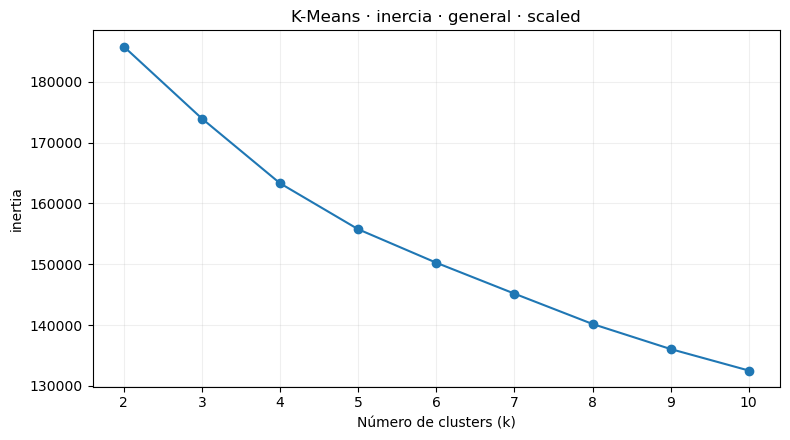

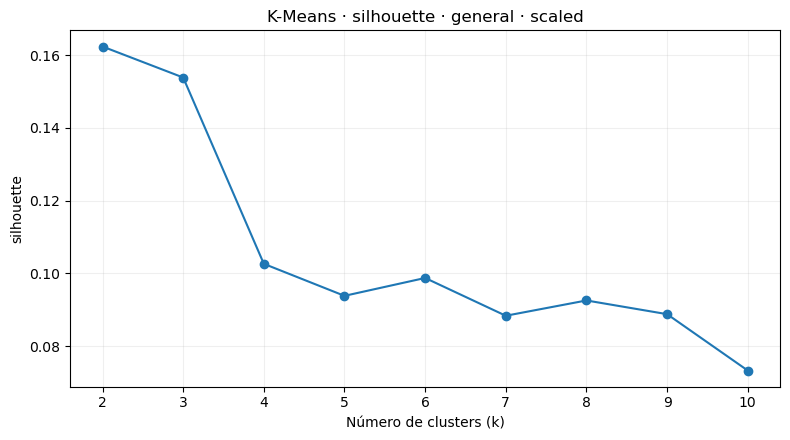

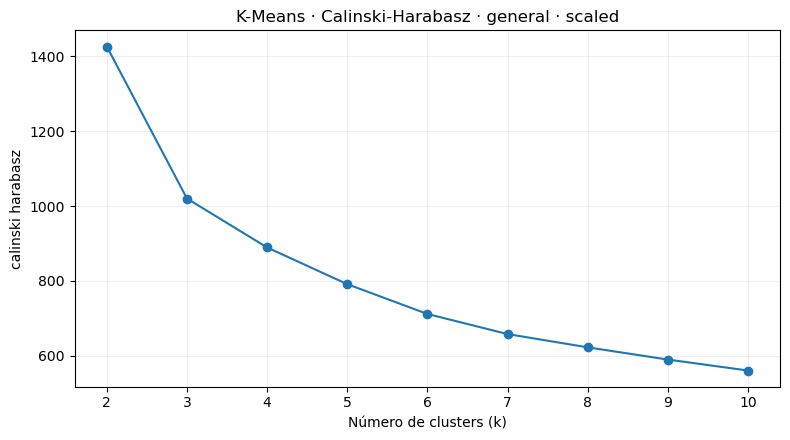

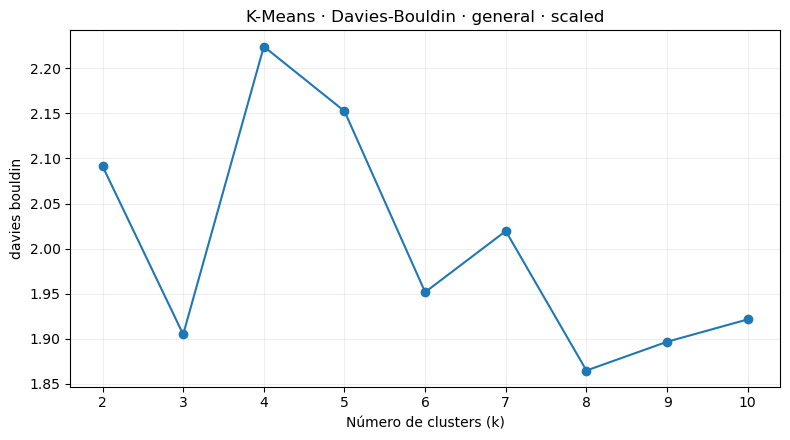

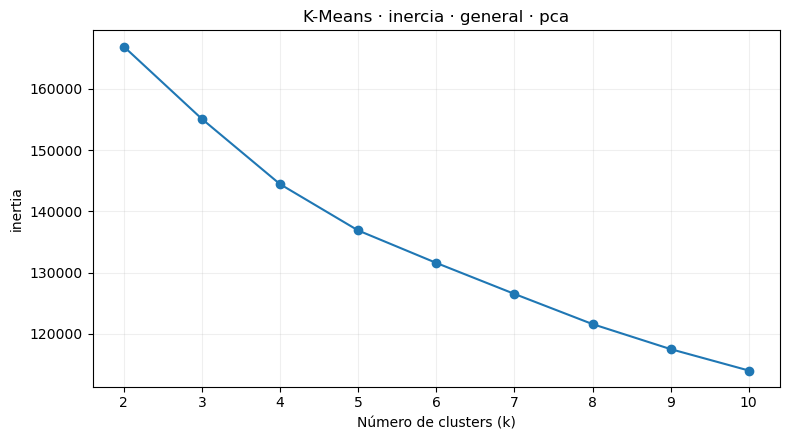

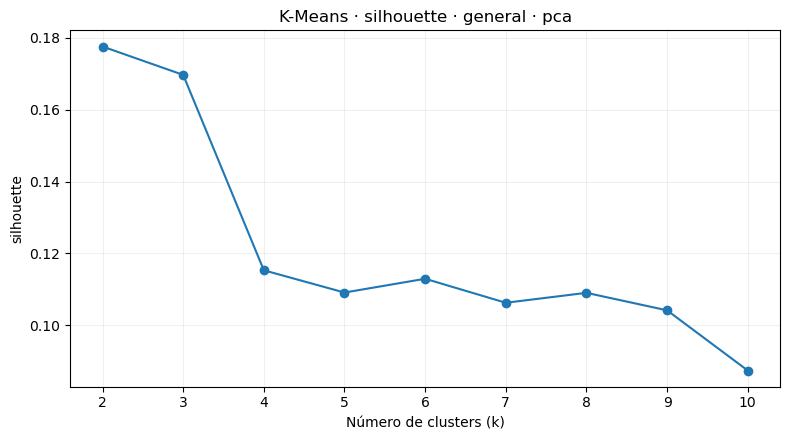

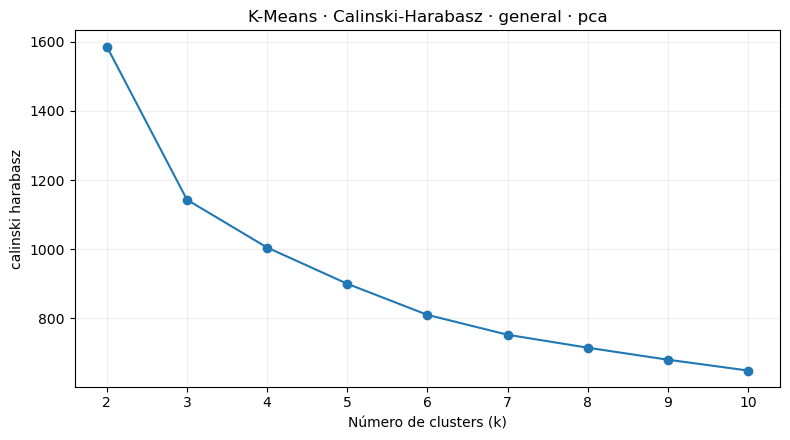

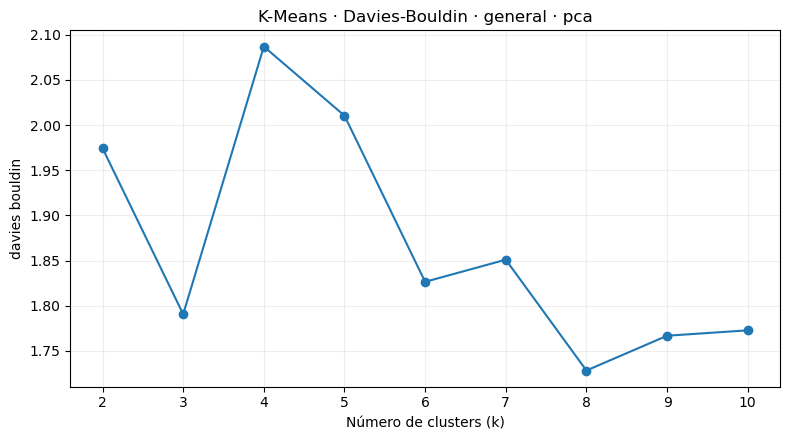

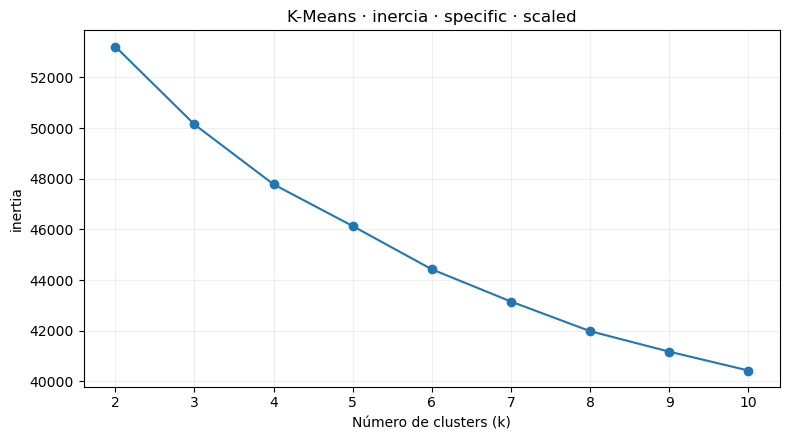

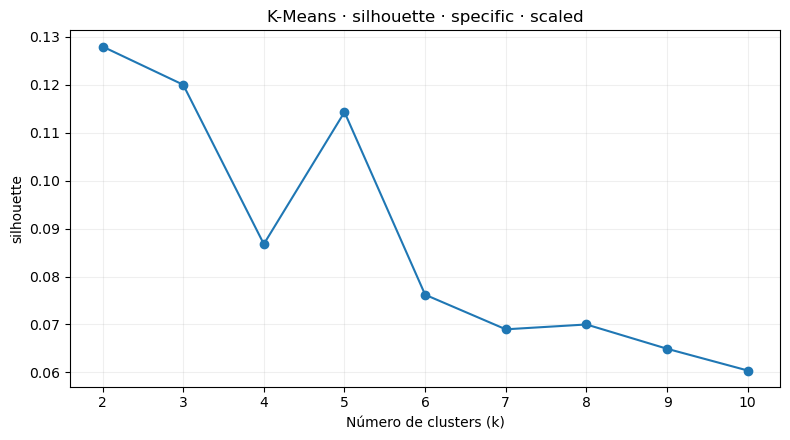

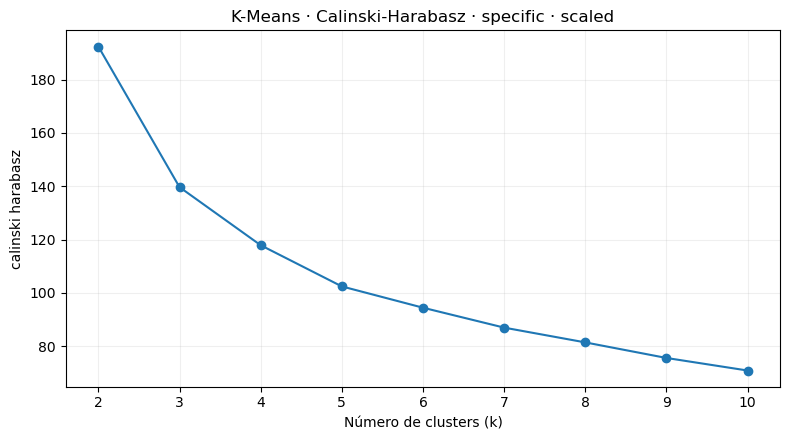

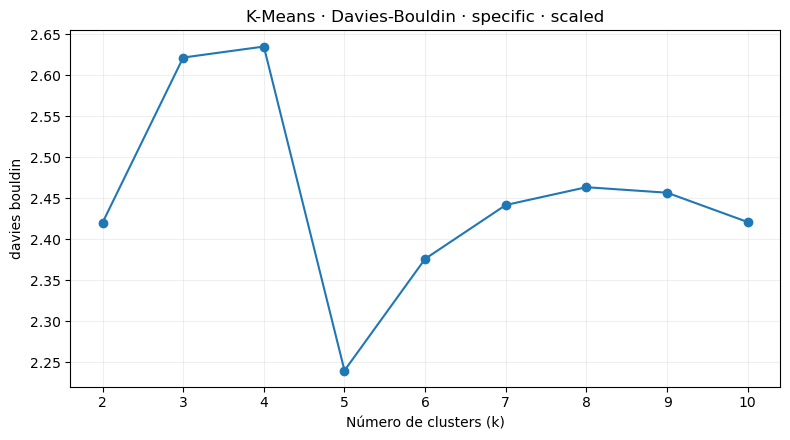

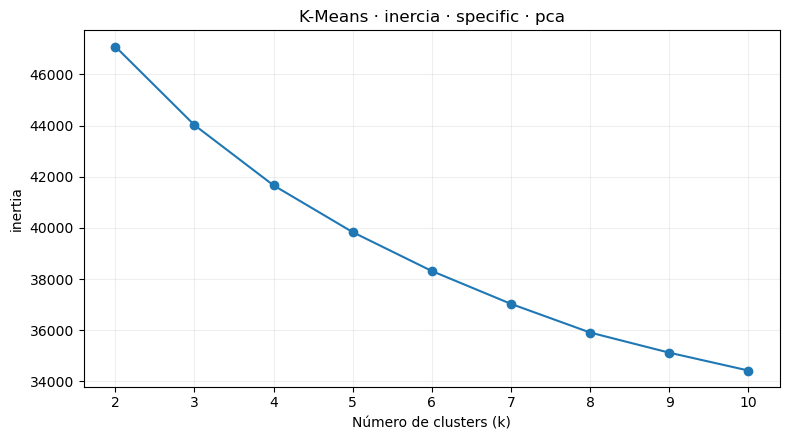

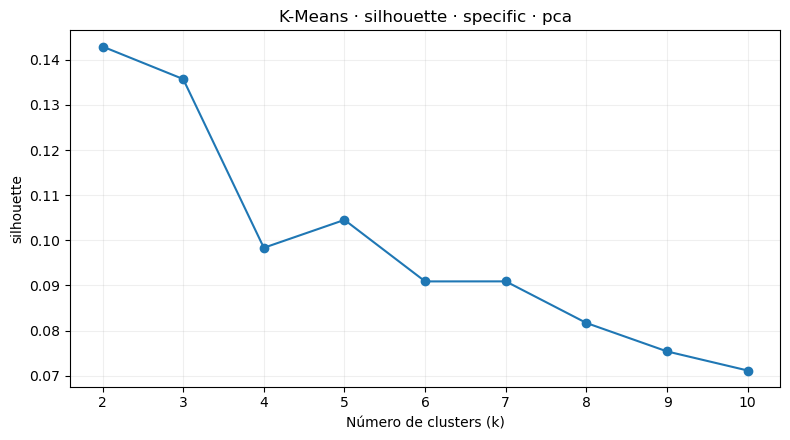

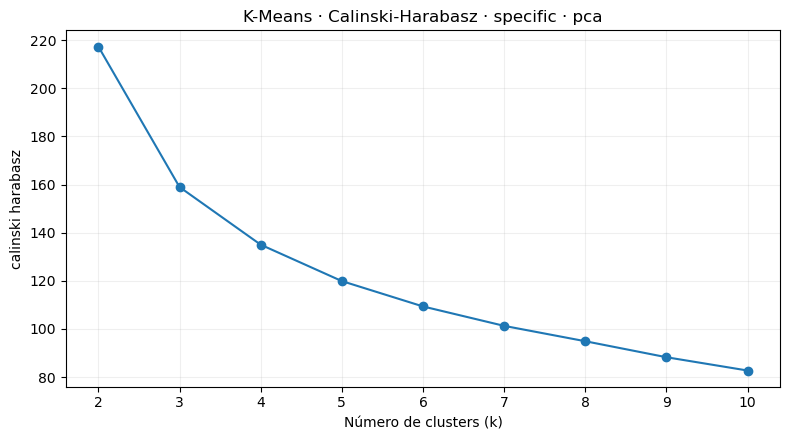

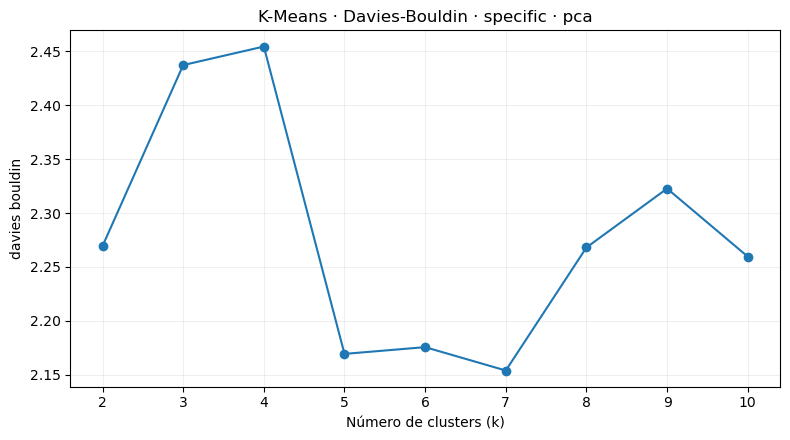

In [36]:
def plot_k_curve(table, universe, space, y, title, filename, higher_is_better=True):
    sub = table.query('universo == @universe and espacio == @space').sort_values('k')
    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.plot(sub['k'], sub[y], marker='o')
    ax.set_xlabel('Número de clusters (k)')
    ax.set_ylabel(y.replace('_', ' '))
    ax.set_title(title)
    ax.grid(alpha=0.2)
    fig.tight_layout()
    plt.show()


for universe in DATASETS:
    for space in DATASETS[universe]:
        plot_k_curve(
            kmeans_results, universe, space, 'inertia',
            f'K-Means · inercia · {universe} · {space}',
            f'20_kmeans_inertia_{space}.png',
            higher_is_better=False,
        )
        plot_k_curve(
            kmeans_results, universe, space, 'silhouette',
            f'K-Means · silhouette · {universe} · {space}',
            f'20_kmeans_silhouette_{space}.png',
        )
        plot_k_curve(
            kmeans_results, universe, space, 'calinski_harabasz',
            f'K-Means · Calinski-Harabasz · {universe} · {space}',
            f'20_kmeans_calinski_harabasz_{space}.png',
        )
        plot_k_curve(
            kmeans_results, universe, space, 'davies_bouldin',
            f'K-Means · Davies-Bouldin · {universe} · {space}',
            f'20_kmeans_davies_bouldin_{space}.png',
            higher_is_better=False,
        )

# Clustering jerárquico · Ward

El criterio de Ward minimiza el aumento de la suma de cuadrados dentro de los clusters al fusionarlos, por lo que es coherente con el uso de distancia euclídea sobre variables estandarizadas.

Se usa `joblib.Memory` para permitir que scikit-learn reutilice el árbol jerárquico completo al evaluar distintos valores de `k` sobre la misma matriz.

In [37]:
def evaluate_ward(universe: str, space: str, X: pd.DataFrame) -> pd.DataFrame:
    rows = []
    with tempfile.TemporaryDirectory(prefix=f'ward_{universe}_{space}_') as cache_dir:
        memory = Memory(location=cache_dir, verbose=0)
        for k in K_VALUES:
            model = AgglomerativeClustering(
                n_clusters=k,
                linkage='ward',
                metric='euclidean',
                compute_full_tree=True,
                memory=memory,
            )
            labels = model.fit_predict(X)
            metrics = cluster_quality_metrics(X, labels, noise_label=-999999)
            rows.append({
                'universo': universe,
                'espacio': space,
                'algoritmo': 'ward',
                'k': k,
                **metrics,
            })
    return pd.DataFrame(rows)


ward_results = pd.concat([
    evaluate_ward(universe, space, X)
    for universe, spaces in DATASETS.items()
    for space, X in spaces.items()
], ignore_index=True)

ward_results = add_warning_flags(ward_results)
display(ward_results.round(4))

,universo,espacio,algoritmo,k,n_clusters,noise_pct,clustered_pct,silhouette,calinski_harabasz,davies_bouldin,min_cluster_n,max_cluster_n,min_cluster_pct,max_cluster_pct,size_entropy_norm,tiny_cluster_warning,high_noise_warning
0,general,scaled,ward,2,2,0.0,100.0,0.1354,1084.3103,2.4148,3166,4442,41.6141,58.3859,0.9796,False,False
1,general,scaled,ward,3,3,0.0,100.0,0.1278,792.2649,2.1891,403,4442,5.2971,58.3859,0.7625,False,False
2,general,scaled,ward,4,4,0.0,100.0,0.0051,661.1465,2.2870,403,3371,5.2971,44.3086,0.8369,False,False
3,general,scaled,ward,5,5,0.0,100.0,0.0157,579.2265,2.4784,403,2763,5.2971,36.3170,0.8608,False,False
4,general,scaled,ward,6,6,0.0,100.0,0.0248,526.4310,2.3288,161,2677,2.1162,35.1866,0.8183,False,False
5,general,scaled,ward,7,7,0.0,100.0,0.0320,491.3246,2.1071,38,2677,0.4995,35.1866,0.7668,True,False
6,general,scaled,ward,8,8,0.0,100.0,0.0394,464.9891,2.0695,38,2564,0.4995,33.7014,0.7752,True,False
7,general,scaled,ward,9,9,0.0,100.0,0.0368,445.5223,2.2453,38,2390,0.4995,31.4143,0.8324,True,False
8,general,scaled,ward,10,10,0.0,100.0,0.0273,425.3527,2.3762,38,1682,0.4995,22.1083,0.8790,True,False
9,general,pca,ward,2,2,0.0,100.0,0.1261,1136.3356,2.3547,3515,4093,46.2014,53.7986,0.9958,False,False


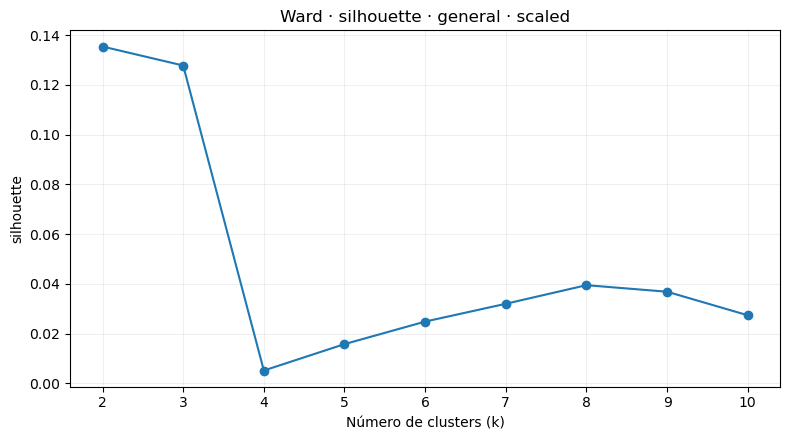

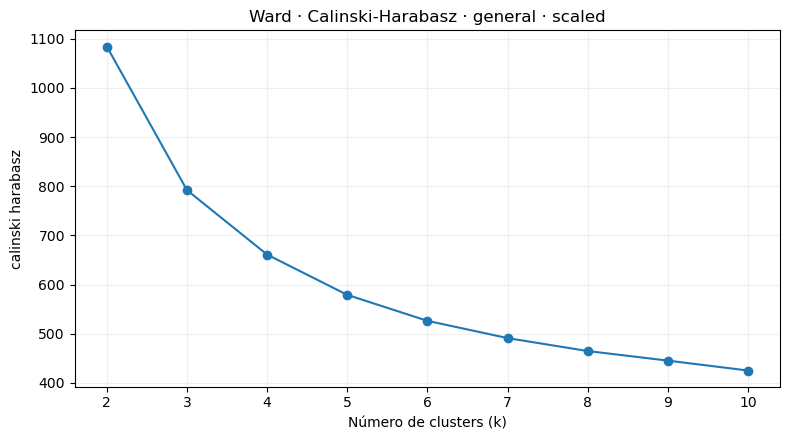

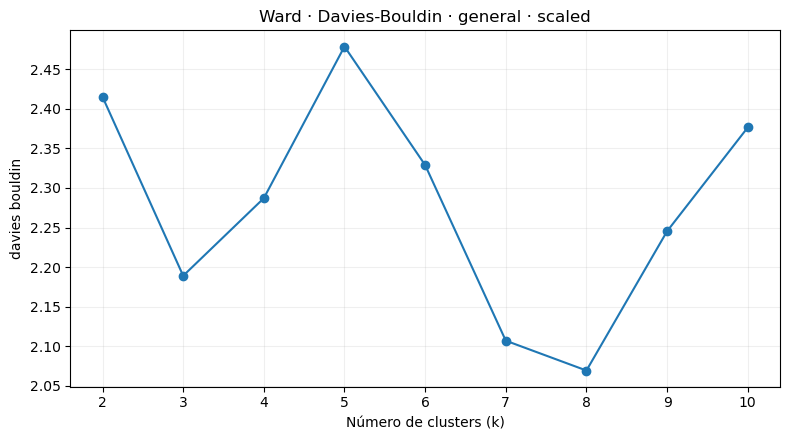

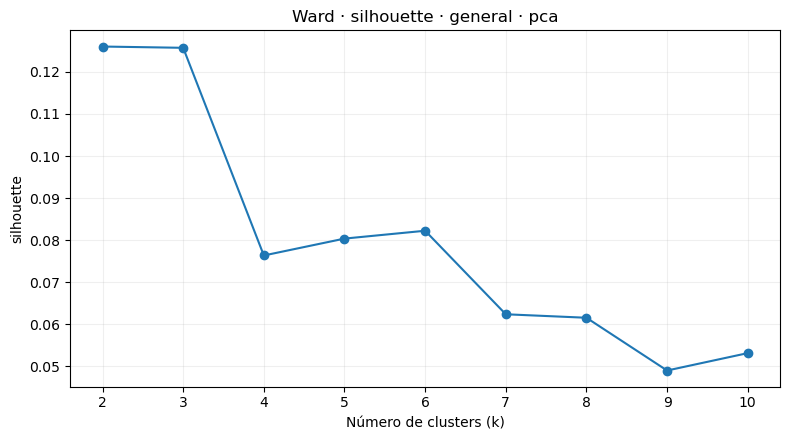

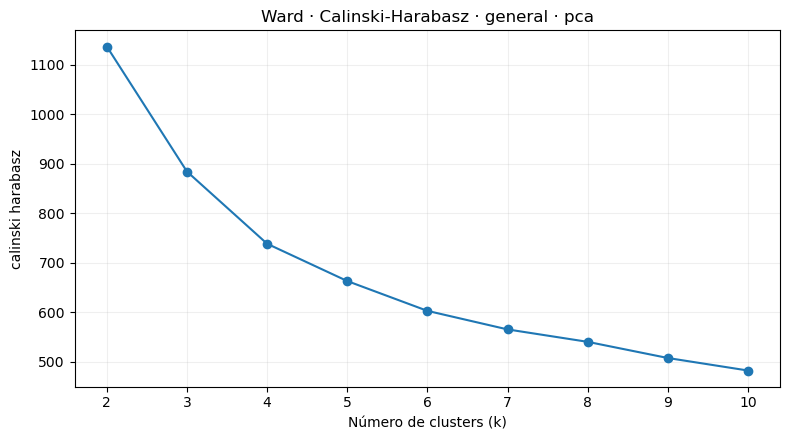

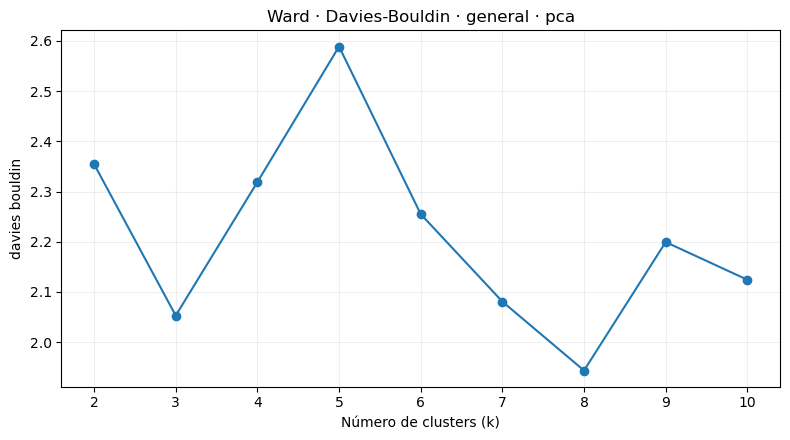

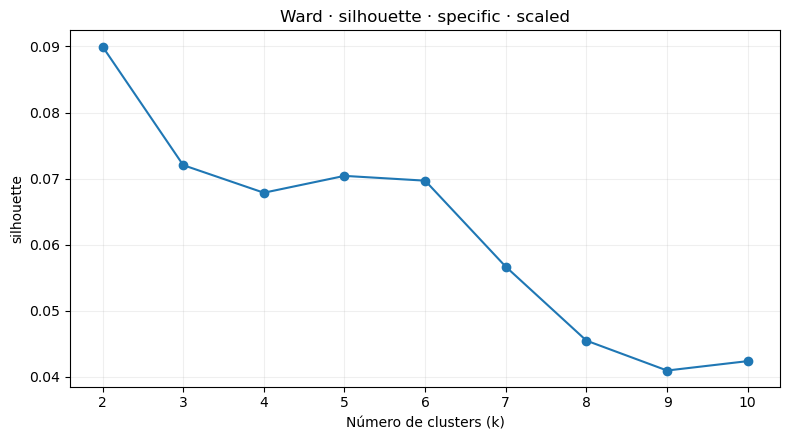

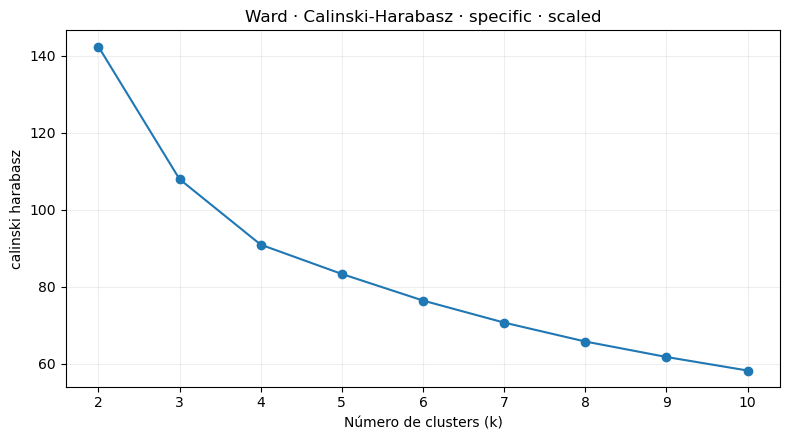

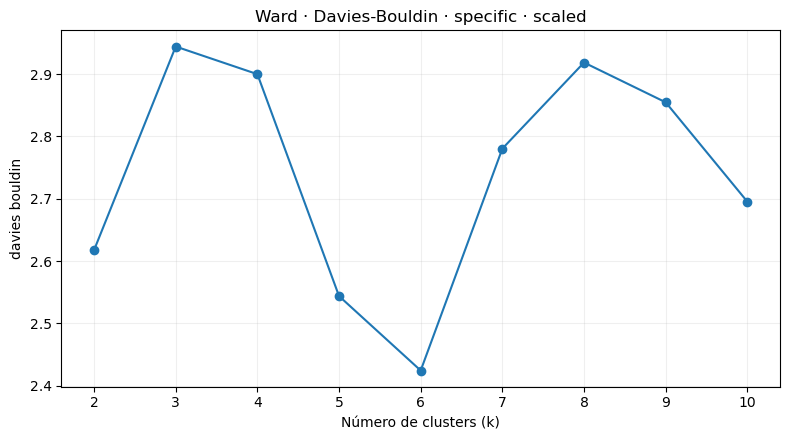

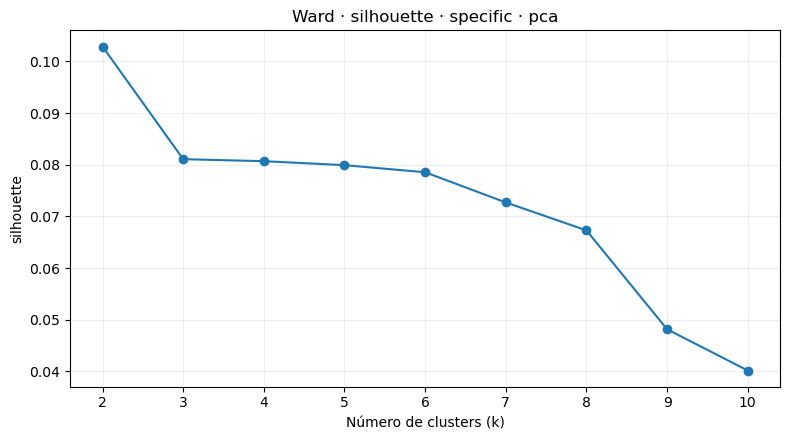

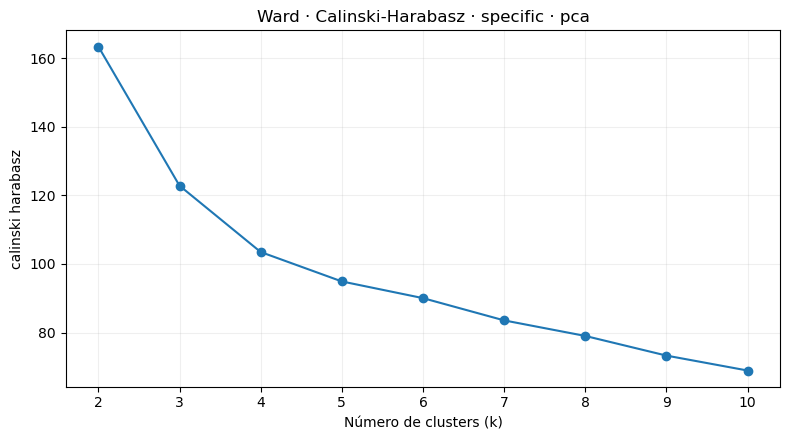

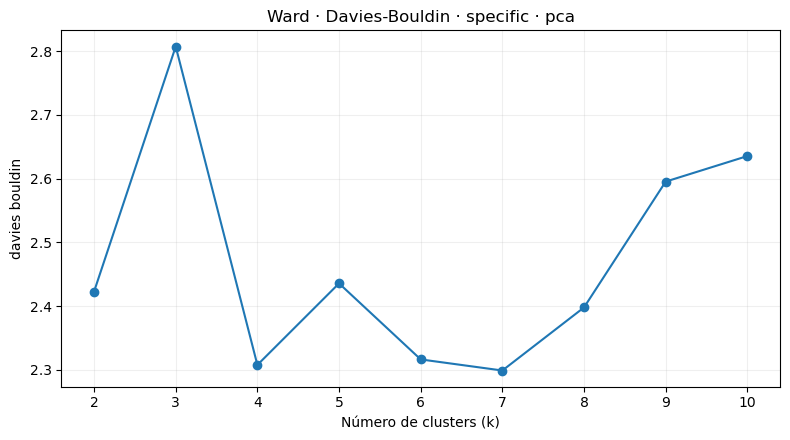

In [38]:
for universe in DATASETS:
    for space in DATASETS[universe]:
        plot_k_curve(
            ward_results, universe, space, 'silhouette',
            f'Ward · silhouette · {universe} · {space}',
            f'21_ward_silhouette_{space}.png',
        )
        plot_k_curve(
            ward_results, universe, space, 'calinski_harabasz',
            f'Ward · Calinski-Harabasz · {universe} · {space}',
            f'21_ward_calinski_harabasz_{space}.png',
        )
        plot_k_curve(
            ward_results, universe, space, 'davies_bouldin',
            f'Ward · Davies-Bouldin · {universe} · {space}',
            f'21_ward_davies_bouldin_{space}.png',
            higher_is_better=False,
        )

## Dendrograma diagnóstico

Se genera sobre una **muestra reproducible** de como máximo 1.500 municipios y usando el espacio PCA. Sirve para observar la estructura jerárquica, no para decidir por sí solo el número final de clusters.

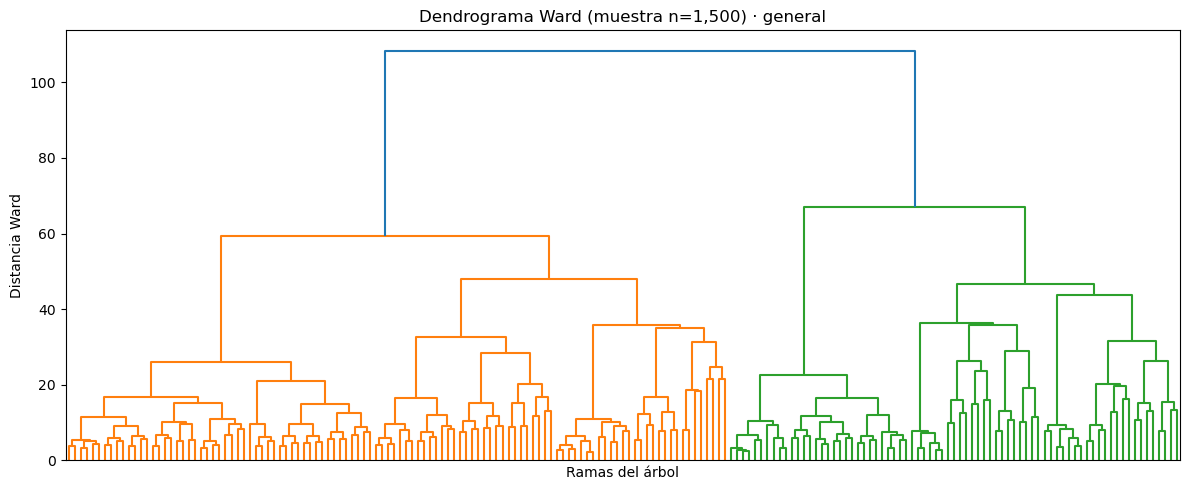

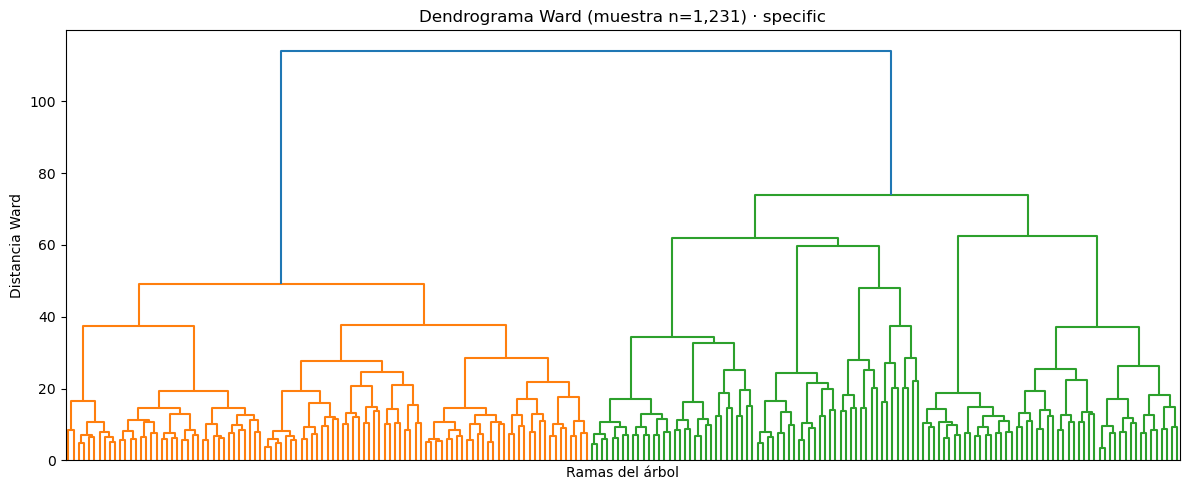

In [39]:
DENDROGRAM_SAMPLE_MAX = 1_500
rng = np.random.default_rng(RANDOM_STATE)

def plot_sample_dendrogram(universe: str, X_pca: pd.DataFrame):
    n = min(DENDROGRAM_SAMPLE_MAX, len(X_pca))
    sample_idx = np.sort(rng.choice(len(X_pca), size=n, replace=False))
    X_sample = X_pca.iloc[sample_idx]

    Z = linkage(X_sample.to_numpy(), method='ward', metric='euclidean')
    fig, ax = plt.subplots(figsize=(12, 5))
    dendrogram(
        Z,
        truncate_mode='level',
        p=7,
        no_labels=True,
        ax=ax,
    )
    ax.set_title(f'Dendrograma Ward (muestra n={n:,}) · {universe}')
    ax.set_xlabel('Ramas del árbol')
    ax.set_ylabel('Distancia Ward')
    fig.tight_layout()
    plt.show()


for universe in DATASETS:
    plot_sample_dendrogram(universe, DATASETS[universe]['pca'])

# Gaussian Mixture Models (GMM)

GMM permite clusters elípticos y pertenencia probabilística. Se comparan covarianzas `full` y `diag` para equilibrar flexibilidad y parsimonia.

Además de las métricas internas, se registran:

- **BIC** y **AIC**: menor es "mejor".
- Convergencia y número de iteraciones.
- Probabilidad posterior máxima media.
- Porcentaje de municipios con probabilidad máxima inferior a 0,60, como indicador de asignaciones fronterizas.

In [40]:
GMM_COVARIANCE_TYPES = ['full', 'diag']
GMM_N_INIT = 3
GMM_MAX_ITER = 300
GMM_REG_COVAR = 1e-6

SILHOUETTE_SAMPLE_SIZE = 1_500

def evaluate_gmm(universe: str, space: str, X: pd.DataFrame) -> pd.DataFrame:
    rows = []
    Xv = X.to_numpy()
    for covariance_type in GMM_COVARIANCE_TYPES:
        for k in K_VALUES:
            model = GaussianMixture(
                n_components=k,
                covariance_type=covariance_type,
                n_init=GMM_N_INIT,
                max_iter=GMM_MAX_ITER,
                reg_covar=GMM_REG_COVAR,
                init_params='kmeans',
                random_state=RANDOM_STATE,
            )
            labels = model.fit_predict(Xv)
            probs = model.predict_proba(Xv)
            confidence = probs.max(axis=1)
            metrics = cluster_quality_metrics(X, labels, noise_label=-999999)
            rows.append({
                'universo': universe,
                'espacio': space,
                'algoritmo': 'gmm',
                'covariance_type': covariance_type,
                'k': k,
                'bic': float(model.bic(Xv)),
                'aic': float(model.aic(Xv)),
                'converged': bool(model.converged_),
                'n_iter': int(model.n_iter_),
                'mean_max_posterior': float(confidence.mean()),
                'low_confidence_pct': float((confidence < 0.60).mean() * 100),
                **metrics,
            })
    return pd.DataFrame(rows)


gmm_results = pd.concat([
    evaluate_gmm(universe, space, X)
    for universe, spaces in DATASETS.items()
    for space, X in spaces.items()
], ignore_index=True)

gmm_results = add_warning_flags(gmm_results)
display(gmm_results.round(4))

,universo,espacio,algoritmo,covariance_type,k,bic,aic,converged,n_iter,mean_max_posterior,low_confidence_pct,n_clusters,noise_pct,clustered_pct,silhouette,calinski_harabasz,davies_bouldin,min_cluster_n,max_cluster_n,min_cluster_pct,max_cluster_pct,size_entropy_norm,tiny_cluster_warning,high_noise_warning
0,general,scaled,gmm,full,2,227123.6708,220679.2390,True,17,0.9997,0.0263,2,0.0,100.0,0.0960,813.8416,2.8117,3451,4157,45.3601,54.6399,0.9938,False,False
1,general,scaled,gmm,full,3,195942.0415,186271.9254,True,25,0.9936,0.3549,3,0.0,100.0,0.0393,433.2497,6.4465,1375,4102,18.0731,53.9169,0.9091,False,False
2,general,scaled,gmm,full,4,185438.4972,172542.6967,True,27,0.9906,0.4995,4,0.0,100.0,0.0222,403.0019,5.3974,911,4044,11.9742,53.1546,0.8556,False,False
3,general,scaled,gmm,full,5,182709.9440,166588.4591,True,17,0.9890,0.5521,5,0.0,100.0,0.0081,337.1719,4.7816,493,4052,6.4800,53.2597,0.8065,False,False
4,general,scaled,gmm,full,6,178334.0590,158986.8898,True,29,0.9869,0.6835,6,0.0,100.0,-0.0335,284.1387,4.2239,404,4114,5.3102,54.0747,0.7839,False,False
5,general,scaled,gmm,full,7,168244.0122,145671.1586,True,30,0.9723,1.3144,7,0.0,100.0,-0.0399,279.9574,4.7903,54,2259,0.7098,29.6924,0.8740,True,False
6,general,scaled,gmm,full,8,162749.6384,136951.1005,True,25,0.9720,1.4984,8,0.0,100.0,-0.0351,268.5335,4.1812,47,2303,0.6178,30.2708,0.8625,True,False
7,general,scaled,gmm,full,9,167408.9414,138384.7192,True,45,0.9848,0.7755,9,0.0,100.0,-0.0607,211.2386,5.1763,46,3559,0.6046,46.7797,0.7806,True,False
8,general,scaled,gmm,full,10,146456.8600,114206.9534,True,73,0.9731,1.3275,10,0.0,100.0,-0.0761,176.0713,6.3235,225,1952,2.9574,25.6572,0.9038,False,False
9,general,scaled,gmm,diag,2,348163.8723,347352.2485,True,14,0.9994,0.0394,2,0.0,100.0,0.0971,825.9474,2.7923,3480,4128,45.7413,54.2587,0.9948,False,False


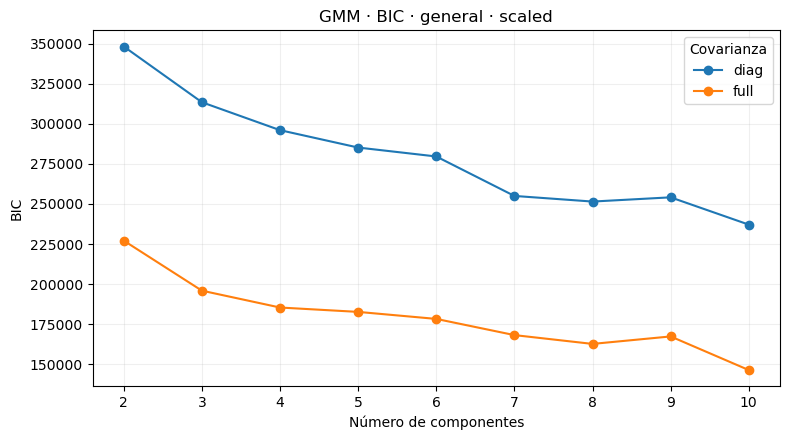

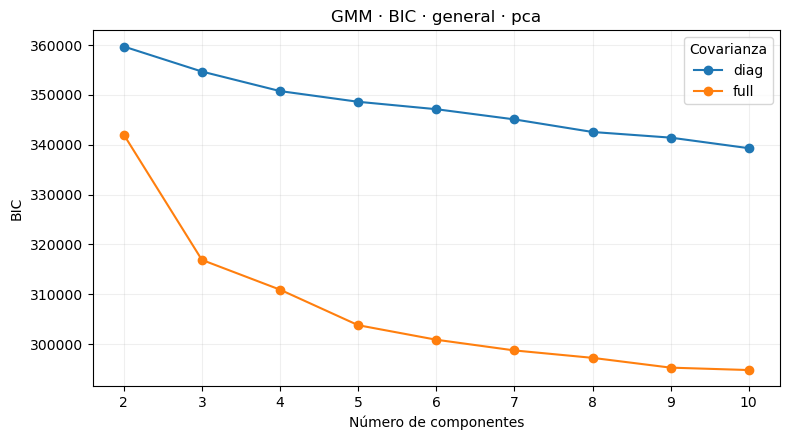

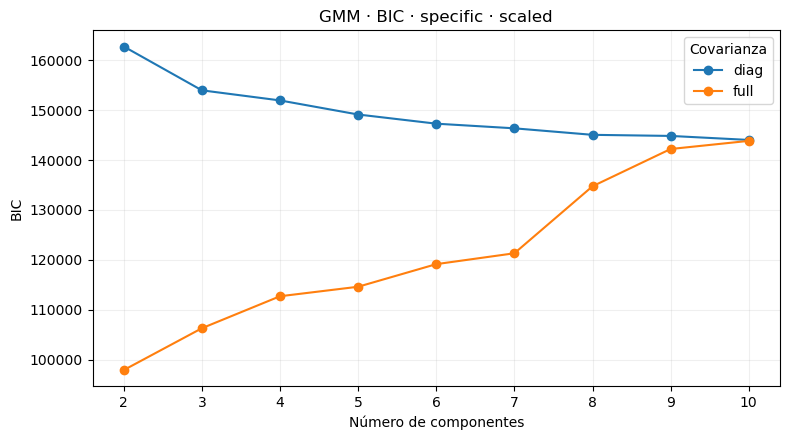

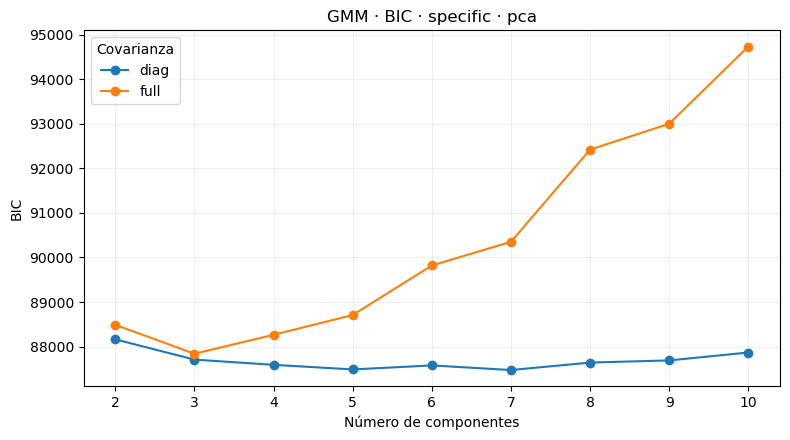

In [41]:
def plot_gmm_bic(table, universe, space):
    sub = table.query('universo == @universe and espacio == @space').copy()
    fig, ax = plt.subplots(figsize=(8, 4.5))
    for covariance_type, group in sub.groupby('covariance_type'):
        group = group.sort_values('k')
        ax.plot(group['k'], group['bic'], marker='o', label=covariance_type)
    ax.set_xlabel('Número de componentes')
    ax.set_ylabel('BIC')
    ax.set_title(f'GMM · BIC · {universe} · {space}')
    ax.legend(title='Covarianza')
    ax.grid(alpha=0.2)
    fig.tight_layout()
    plt.show()


for universe in DATASETS:
    for space in DATASETS[universe]:
        plot_gmm_bic(gmm_results, universe, space)

# HDBSCAN · análisis de densidad complementario

HDBSCAN no necesita fijar un único `eps` y puede identificar clusters con densidades diferentes, además de observaciones marcadas como ruido (`-1`).

Por defecto lo ejecutaremos sobre PCA.

Se exploran varios valores de `min_cluster_size` y `min_samples`. La proporción de ruido se interpreta junto con las métricas calculadas **solo sobre los municipios asignados a clusters**.

In [43]:
# HDBSCAN: se construyen tamaños mínimos como fracción de cada universo.
HDBSCAN_MIN_CLUSTER_FRACTIONS = [0.005, 0.01, 0.02, 0.05]
HDBSCAN_MIN_SAMPLES_VALUES = [5, 10, 20]
RUN_HDBSCAN_ON_SCALED = False

def _hdbscan_min_cluster_sizes(n: int) -> list[int]:
    values = {
        max(10, int(round(n * frac)))
        for frac in HDBSCAN_MIN_CLUSTER_FRACTIONS
    }
    return sorted(v for v in values if v < n)


def make_hdbscan(min_cluster_size: int, min_samples: int):
    if HDBSCAN is None:
        raise ImportError(
            'HDBSCAN no está disponible. Actualiza scikit-learn o instala: %pip install hdbscan'
        )

    if HDBSCAN_BACKEND == 'sklearn':
        return HDBSCAN(
            min_cluster_size=min_cluster_size,
            min_samples=min_samples,
            metric='euclidean',
            cluster_selection_method='eom',
            allow_single_cluster=False,
            n_jobs=-1,
            copy=True,
        )

    return HDBSCAN(
        min_cluster_size=min_cluster_size,
        min_samples=min_samples,
        metric='euclidean',
        cluster_selection_method='eom',
        allow_single_cluster=False,
        core_dist_n_jobs=-1,
        prediction_data=True,
    )


def evaluate_hdbscan(universe: str, space: str, X: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for min_cluster_size in _hdbscan_min_cluster_sizes(len(X)):
        for min_samples in HDBSCAN_MIN_SAMPLES_VALUES:
            if min_samples > min_cluster_size:
                continue
            model = make_hdbscan(min_cluster_size, min_samples)
            labels = model.fit_predict(X)
            metrics = cluster_quality_metrics(X, labels, noise_label=-1)
            probabilities = getattr(model, 'probabilities_', None)
            rows.append({
                'universo': universe,
                'espacio': space,
                'algoritmo': 'hdbscan',
                'min_cluster_size': min_cluster_size,
                'min_samples': min_samples,
                'mean_membership_strength': (
                    float(np.mean(probabilities[labels != -1]))
                    if probabilities is not None and np.any(labels != -1)
                    else np.nan
                ),
                **metrics,
            })
    return pd.DataFrame(rows)


hdbscan_frames = []
if HDBSCAN is not None:
    for universe, spaces in DATASETS.items():
        spaces_to_run = ['pca'] + (['scaled'] if RUN_HDBSCAN_ON_SCALED else [])
        for space in spaces_to_run:
            hdbscan_frames.append(evaluate_hdbscan(universe, space, spaces[space]))

if hdbscan_frames:
    hdbscan_results = pd.concat(hdbscan_frames, ignore_index=True)
    hdbscan_results = add_warning_flags(hdbscan_results)
    display(hdbscan_results.round(4))
else:
    hdbscan_results = pd.DataFrame()

,universo,espacio,algoritmo,min_cluster_size,min_samples,mean_membership_strength,n_clusters,noise_pct,clustered_pct,silhouette,calinski_harabasz,davies_bouldin,min_cluster_n,max_cluster_n,min_cluster_pct,max_cluster_pct,size_entropy_norm,tiny_cluster_warning,high_noise_warning
0,general,pca,hdbscan,38,5,NaN,0,100.0000,0.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,True
1,general,pca,hdbscan,38,10,NaN,0,100.0000,0.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,True
2,general,pca,hdbscan,38,20,NaN,0,100.0000,0.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,True
3,general,pca,hdbscan,76,5,NaN,0,100.0000,0.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,True
4,general,pca,hdbscan,76,10,NaN,0,100.0000,0.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,True
5,general,pca,hdbscan,76,20,NaN,0,100.0000,0.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,True
6,general,pca,hdbscan,152,5,NaN,0,100.0000,0.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,True
7,general,pca,hdbscan,152,10,NaN,0,100.0000,0.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,True
8,general,pca,hdbscan,152,20,NaN,0,100.0000,0.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,True
9,general,pca,hdbscan,380,5,NaN,0,100.0000,0.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,True


HDBSCAN no ha identificado una estructura de densidad adecuada para segmentar de forma general los municipios. En el universo general, todas las configuraciones evaluadas clasificaron el 100 % de las observaciones como ruido. En el universo específico, solamente las configuraciones menos restrictivas detectaron dos pequeños conglomerados, pero dejando entre el 95 % y el 98 % de los municipios sin asignar.

Por ello, descartaremos HDBSCAN como método de clustering para este trabajo.

# Preselección multi criterio

No se escogerá directamente el modelo con el silhouette máximo de forma aislada. Para decidir qué configuraciones merecen una validación de estabilidad se construye un ranking dentro de cada familia y espacio:

- rango de silhouette (descendente),
- rango de Calinski-Harabasz (descendente),
- rango de Davies-Bouldin (ascendente),
- BIC adicional en GMM.

El promedio de rangos solo se utiliza para preseleccionar configuraciones. No es el criterio final.

In [44]:
TOP_CANDIDATES_PER_FAMILY_SPACE = 1

def diagnostic_rank(table: pd.DataFrame, include_bic: bool = False) -> pd.DataFrame:
    out = table.copy()
    valid = (
        out['silhouette'].notna()
        & out['calinski_harabasz'].notna()
        & out['davies_bouldin'].notna()
        & (out['n_clusters'] >= 2)
    )
    out = out.loc[valid].copy()

    if out.empty:
        return out

    out['rank_silhouette'] = out['silhouette'].rank(ascending=False, method='min')
    out['rank_ch'] = out['calinski_harabasz'].rank(ascending=False, method='min')
    out['rank_db'] = out['davies_bouldin'].rank(ascending=True, method='min')

    rank_cols = ['rank_silhouette', 'rank_ch', 'rank_db']
    if include_bic and 'bic' in out.columns:
        out['rank_bic'] = out['bic'].rank(ascending=True, method='min')
        rank_cols.append('rank_bic')

    out['diagnostic_rank_mean'] = out[rank_cols].mean(axis=1)
    return out.sort_values('diagnostic_rank_mean')


def shortlist_family_space(table, include_bic=False, top_n=TOP_CANDIDATES_PER_FAMILY_SPACE):
    rows = []
    for (universe, space), group in table.groupby(['universo', 'espacio']):
        ranked = diagnostic_rank(group, include_bic=include_bic)
        if not ranked.empty:
            rows.append(ranked.head(top_n))
    return pd.concat(rows, ignore_index=True) if rows else pd.DataFrame()


short_kmeans = shortlist_family_space(kmeans_results)
short_ward = shortlist_family_space(ward_results)
short_gmm = shortlist_family_space(gmm_results, include_bic=True)

if not hdbscan_results.empty:
    # La proporción de ruido se conserva como criterio separado; no se altera el silhouette real.
    short_hdbscan = shortlist_family_space(hdbscan_results)
else:
    short_hdbscan = pd.DataFrame()

shortlist = pd.concat(
    [x for x in [short_kmeans, short_ward, short_gmm, short_hdbscan] if not x.empty],
    ignore_index=True,
    sort=False,
)

display(shortlist.round(4))

,universo,espacio,algoritmo,k,inertia,n_iter,n_clusters,noise_pct,clustered_pct,silhouette,calinski_harabasz,davies_bouldin,min_cluster_n,max_cluster_n,min_cluster_pct,max_cluster_pct,size_entropy_norm,tiny_cluster_warning,high_noise_warning,rank_silhouette,rank_ch,rank_db,diagnostic_rank_mean,covariance_type,bic,aic,converged,mean_max_posterior,low_confidence_pct,rank_bic,min_cluster_size,min_samples,mean_membership_strength
0,general,pca,kmeans,3.0,155104.1588,14.0,3,0.0000,100.0000,0.1697,1143.2016,1.7907,328.0,4238.0,4.3113,55.7045,0.7537,False,False,2.0,2.0,4.0,2.6667,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,general,scaled,kmeans,3.0,173969.1340,11.0,3,0.0000,100.0000,0.1539,1019.9257,1.9048,338.0,4234.0,4.4427,55.6519,0.7565,False,False,2.0,2.0,3.0,2.3333,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,specific,pca,kmeans,2.0,47092.4340,11.0,2,0.0000,100.0000,0.1430,217.3750,2.2694,609.0,622.0,49.4720,50.5280,0.9999,False,False,1.0,1.0,6.0,2.6667,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,specific,scaled,kmeans,2.0,53216.8553,12.0,2,0.0000,100.0000,0.1280,192.4472,2.4202,609.0,622.0,49.4720,50.5280,0.9999,False,False,1.0,1.0,3.0,1.6667,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,general,pca,ward,3.0,NaN,NaN,3,0.0000,100.0000,0.1257,883.7532,2.0531,297.0,3796.0,3.9038,49.8948,0.7557,False,False,2.0,2.0,2.0,2.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,general,scaled,ward,3.0,NaN,NaN,3,0.0000,100.0000,0.1278,792.2649,2.1891,403.0,4442.0,5.2971,58.3859,0.7625,False,False,2.0,2.0,3.0,2.3333,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,specific,pca,ward,2.0,NaN,NaN,2,0.0000,100.0000,0.1029,163.4523,2.4228,425.0,806.0,34.5248,65.4752,0.9298,False,False,1.0,1.0,5.0,2.3333,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,specific,scaled,ward,2.0,NaN,NaN,2,0.0000,100.0000,0.0900,142.4417,2.6176,425.0,806.0,34.5248,65.4752,0.9298,False,False,1.0,1.0,3.0,1.6667,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,general,pca,gmm,2.0,NaN,22.0,2,0.0000,100.0000,0.0911,784.1549,2.8570,3648.0,3960.0,47.9495,52.0505,0.9988,False,False,2.0,1.0,1.0,3.7500,full,342041.2263,339675.7244,True,0.9875,0.7098,11.0,NaN,NaN,NaN
9,general,scaled,gmm,2.0,NaN,17.0,2,0.0000,100.0000,0.0960,813.8416,2.8117,3451.0,4157.0,45.3601,54.6399,0.9938,False,False,2.0,2.0,2.0,3.7500,full,227123.6708,220679.2390,True,0.9997,0.0263,9.0,NaN,NaN,NaN


# Estabilidad por remuestreo

Una segmentación que depende demasiado de pequeñas variaciones de la muestra no es una base sólida para interpretar tipos de mercado.

Para cada candidato:

1. se extraen varias submuestras sin reemplazo del 80 %;
2. se vuelve a ajustar el algoritmo con la misma configuración;
3. para cada par de ejecuciones se comparan las etiquetas de los municipios presentes en ambas submuestras;
4. se calcula **Adjusted Rand Index (ARI)**, que es invariante al nombre arbitrario de los clusters.

En HDBSCAN, el ARI se calcula sobre los puntos que no son ruido en ninguna de las dos ejecuciones comparadas. También se guarda la cobertura media de la comparación.

In [45]:
STABILITY_RUNS = 8
STABILITY_SAMPLE_FRACTION = 0.80

def fit_labels_from_config(X: pd.DataFrame, config: dict, seed: int = RANDOM_STATE):
    algo = config['algoritmo']

    if algo == 'kmeans':
        model = KMeans(
            n_clusters=int(config['k']),
            init='k-means++',
            n_init=KMEANS_N_INIT,
            max_iter=KMEANS_MAX_ITER,
            random_state=seed,
        )
        labels = model.fit_predict(X)
        return model, labels

    if algo == 'ward':
        model = AgglomerativeClustering(
            n_clusters=int(config['k']),
            linkage='ward',
            metric='euclidean',
        )
        labels = model.fit_predict(X)
        return model, labels

    if algo == 'gmm':
        model = GaussianMixture(
            n_components=int(config['k']),
            covariance_type=str(config['covariance_type']),
            n_init=GMM_N_INIT,
            max_iter=GMM_MAX_ITER,
            reg_covar=GMM_REG_COVAR,
            init_params='kmeans',
            random_state=seed,
        )
        labels = model.fit_predict(X.to_numpy())
        return model, labels

    if algo == 'hdbscan':
        model = make_hdbscan(
            int(config['min_cluster_size']),
            int(config['min_samples']),
        )
        labels = model.fit_predict(X)
        return model, labels

    raise ValueError(f'Algoritmo no soportado: {algo}')


def resampling_stability(
    X: pd.DataFrame,
    config: dict,
    n_runs: int = STABILITY_RUNS,
    fraction: float = STABILITY_SAMPLE_FRACTION,
    base_seed: int = RANDOM_STATE,
) -> dict:
    n = len(X)
    sample_n = max(2, int(round(n * fraction)))
    runs = []

    for run in range(n_runs):
        local_rng = np.random.default_rng(base_seed + run)
        pos = np.sort(local_rng.choice(n, size=sample_n, replace=False))
        X_sub = X.iloc[pos]
        _, labels = fit_labels_from_config(X_sub, config, seed=base_seed + run)
        runs.append((pos, np.asarray(labels)))

    aris = []
    coverage = []
    for (pos_a, lab_a), (pos_b, lab_b) in combinations(runs, 2):
        common, ia, ib = np.intersect1d(pos_a, pos_b, return_indices=True)
        la = lab_a[ia]
        lb = lab_b[ib]

        if config['algoritmo'] == 'hdbscan':
            mask = (la != -1) & (lb != -1)
        else:
            mask = np.ones(len(common), dtype=bool)

        coverage.append(float(mask.mean()) if len(mask) else np.nan)
        if mask.sum() < 20:
            continue
        if len(np.unique(la[mask])) < 2 or len(np.unique(lb[mask])) < 2:
            continue
        aris.append(float(adjusted_rand_score(la[mask], lb[mask])))

    return {
        'stability_ari_mean': float(np.mean(aris)) if aris else np.nan,
        'stability_ari_median': float(np.median(aris)) if aris else np.nan,
        'stability_ari_std': float(np.std(aris)) if aris else np.nan,
        'stability_pairwise_comparisons': len(aris),
        'stability_comparison_coverage_mean': float(np.nanmean(coverage)) if coverage else np.nan,
    }


stability_rows = []
for _, row in shortlist.iterrows():
    config = row.to_dict()
    X = DATASETS[config['universo']][config['espacio']]
    print(
        f"Estabilidad: {config['universo']} · {config['espacio']} · "
        f"{config['algoritmo']}"
    )
    stability = resampling_stability(X, config)
    stability_rows.append({
        **config,
        **stability,
    })

stability_results = pd.DataFrame(stability_rows)
display(stability_results.round(4))

Estabilidad: general · pca · kmeans
Estabilidad: general · scaled · kmeans
Estabilidad: specific · pca · kmeans
Estabilidad: specific · scaled · kmeans
Estabilidad: general · pca · ward
Estabilidad: general · scaled · ward
Estabilidad: specific · pca · ward
Estabilidad: specific · scaled · ward
Estabilidad: general · pca · gmm
Estabilidad: general · scaled · gmm
Estabilidad: specific · pca · gmm
Estabilidad: specific · scaled · gmm
Estabilidad: specific · pca · hdbscan


,universo,espacio,algoritmo,k,inertia,n_iter,n_clusters,noise_pct,clustered_pct,silhouette,calinski_harabasz,davies_bouldin,min_cluster_n,max_cluster_n,min_cluster_pct,max_cluster_pct,size_entropy_norm,tiny_cluster_warning,high_noise_warning,rank_silhouette,rank_ch,rank_db,diagnostic_rank_mean,covariance_type,bic,aic,converged,mean_max_posterior,low_confidence_pct,rank_bic,min_cluster_size,min_samples,mean_membership_strength,stability_ari_mean,stability_ari_median,stability_ari_std,stability_pairwise_comparisons,stability_comparison_coverage_mean
0,general,pca,kmeans,3.0,155104.1588,14.0,3,0.0000,100.0000,0.1697,1143.2016,1.7907,328.0,4238.0,4.3113,55.7045,0.7537,False,False,2.0,2.0,4.0,2.6667,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.6273,0.3435,0.3228,28,1.0000
1,general,scaled,kmeans,3.0,173969.1340,11.0,3,0.0000,100.0000,0.1539,1019.9257,1.9048,338.0,4234.0,4.4427,55.6519,0.7565,False,False,2.0,2.0,3.0,2.3333,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.6231,0.3427,0.3190,28,1.0000
2,specific,pca,kmeans,2.0,47092.4340,11.0,2,0.0000,100.0000,0.1430,217.3750,2.2694,609.0,622.0,49.4720,50.5280,0.9999,False,False,1.0,1.0,6.0,2.6667,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.9470,0.9400,0.0384,28,1.0000
3,specific,scaled,kmeans,2.0,53216.8553,12.0,2,0.0000,100.0000,0.1280,192.4472,2.4202,609.0,622.0,49.4720,50.5280,0.9999,False,False,1.0,1.0,3.0,1.6667,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.9463,0.9399,0.0385,28,1.0000
4,general,pca,ward,3.0,NaN,NaN,3,0.0000,100.0000,0.1257,883.7532,2.0531,297.0,3796.0,3.9038,49.8948,0.7557,False,False,2.0,2.0,2.0,2.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.3886,0.3591,0.1059,28,1.0000
5,general,scaled,ward,3.0,NaN,NaN,3,0.0000,100.0000,0.1278,792.2649,2.1891,403.0,4442.0,5.2971,58.3859,0.7625,False,False,2.0,2.0,3.0,2.3333,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.3713,0.3731,0.0902,28,1.0000
6,specific,pca,ward,2.0,NaN,NaN,2,0.0000,100.0000,0.1029,163.4523,2.4228,425.0,806.0,34.5248,65.4752,0.9298,False,False,1.0,1.0,5.0,2.3333,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.4869,0.4786,0.1333,28,1.0000
7,specific,scaled,ward,2.0,NaN,NaN,2,0.0000,100.0000,0.0900,142.4417,2.6176,425.0,806.0,34.5248,65.4752,0.9298,False,False,1.0,1.0,3.0,1.6667,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.4491,0.4781,0.0984,28,1.0000
8,general,pca,gmm,2.0,NaN,22.0,2,0.0000,100.0000,0.0911,784.1549,2.8570,3648.0,3960.0,47.9495,52.0505,0.9988,False,False,2.0,1.0,1.0,3.7500,full,342041.2263,339675.7244,True,0.9875,0.7098,11.0,NaN,NaN,NaN,0.9626,0.9699,0.0228,28,1.0000
9,general,scaled,gmm,2.0,NaN,17.0,2,0.0000,100.0000,0.0960,813.8416,2.8117,3451.0,4157.0,45.3601,54.6399,0.9938,False,False,2.0,2.0,2.0,3.7500,full,227123.6708,220679.2390,True,0.9997,0.0263,9.0,NaN,NaN,NaN,0.9931,0.9959,0.0059,28,1.0000


# Acuerdo entre algoritmos

La estabilidad evalúa si una solución reaparece al perturbar la muestra. El acuerdo entre algoritmos responde a otra pregunta: **¿métodos con supuestos distintos están encontrando estructuras parecidas?**

Se reajusta cada candidato sobre el universo completo y se calculan matrices de:

- Adjusted Rand Index (ARI)
- Adjusted Mutual Information (AMI)

HDBSCAN puede dejar observaciones como ruido; para compararlo con los demás métodos, las métricas se calculan sobre las observaciones no marcadas como ruido por HDBSCAN.

In [47]:
def config_name(config: dict) -> str:
    algo = config['algoritmo']
    space = config['espacio']
    if algo in {'kmeans', 'ward'}:
        return f"{algo}_{space}_k{int(config['k'])}"
    if algo == 'gmm':
        return f"gmm_{space}_{config['covariance_type']}_k{int(config['k'])}"
    if algo == 'hdbscan':
        return (
            f"hdbscan_{space}_mcs{int(config['min_cluster_size'])}"
            f"_ms{int(config['min_samples'])}"
        )
    return f'{algo}_{space}'


candidate_models = {'general': {}, 'specific': {}}
candidate_labels = {'general': {}, 'specific': {}}

for _, row in stability_results.iterrows():
    config = row.to_dict()
    universe = config['universo']
    X = DATASETS[universe][config['espacio']]
    model, labels = fit_labels_from_config(X, config)
    name = config_name(config)
    candidate_models[universe][name] = model
    candidate_labels[universe][name] = np.asarray(labels)


def agreement_matrices(label_dict: dict):
    names = list(label_dict)
    ari = pd.DataFrame(np.eye(len(names)), index=names, columns=names, dtype=float)
    ami = pd.DataFrame(np.eye(len(names)), index=names, columns=names, dtype=float)

    for a, b in combinations(names, 2):
        la = label_dict[a]
        lb = label_dict[b]
        mask = (la != -1) & (lb != -1)
        if mask.sum() < 20 or len(np.unique(la[mask])) < 2 or len(np.unique(lb[mask])) < 2:
            ari.loc[a, b] = ari.loc[b, a] = np.nan
            ami.loc[a, b] = ami.loc[b, a] = np.nan
        else:
            ari_value = adjusted_rand_score(la[mask], lb[mask])
            ami_value = adjusted_mutual_info_score(la[mask], lb[mask])
            ari.loc[a, b] = ari.loc[b, a] = ari_value
            ami.loc[a, b] = ami.loc[b, a] = ami_value
    return ari, ami


AGREEMENT = {}
for universe in DATASETS:
    ari, ami = agreement_matrices(candidate_labels[universe])
    AGREEMENT[universe] = {'ari': ari, 'ami': ami}
    print(f'ARI · {universe}')
    display(ari.round(3))
    print(f'AMI · {universe}')
    display(ami.round(3))

ARI · general


,kmeans_pca_k3,kmeans_scaled_k3,ward_pca_k3,ward_scaled_k3,gmm_pca_full_k2,gmm_scaled_full_k2
kmeans_pca_k3,1.000,0.994,0.442,0.519,0.269,0.326
kmeans_scaled_k3,0.994,1.000,0.443,0.518,0.269,0.327
ward_pca_k3,0.442,0.443,1.000,0.350,0.257,0.296
ward_scaled_k3,0.519,0.518,0.350,1.000,0.249,0.278
gmm_pca_full_k2,0.269,0.269,0.257,0.249,1.000,0.726
gmm_scaled_full_k2,0.326,0.327,0.296,0.278,0.726,1.000


AMI · general


,kmeans_pca_k3,kmeans_scaled_k3,ward_pca_k3,ward_scaled_k3,gmm_pca_full_k2,gmm_scaled_full_k2
kmeans_pca_k3,1.000,0.982,0.417,0.430,0.226,0.265
kmeans_scaled_k3,0.982,1.000,0.420,0.431,0.227,0.266
ward_pca_k3,0.417,0.420,1.000,0.347,0.223,0.259
ward_scaled_k3,0.430,0.431,0.347,1.000,0.218,0.232
gmm_pca_full_k2,0.226,0.227,0.223,0.218,1.000,0.624
gmm_scaled_full_k2,0.265,0.266,0.259,0.232,0.624,1.000


ARI · specific


,kmeans_pca_k2,kmeans_scaled_k2,ward_pca_k2,ward_scaled_k2,gmm_pca_full_k7,gmm_scaled_full_k7,hdbscan_pca_mcs10_ms5
kmeans_pca_k2,1.000,0.958,0.415,0.398,0.228,0.207,0.429
kmeans_scaled_k2,0.958,1.000,0.438,0.425,0.222,0.217,0.429
ward_pca_k2,0.415,0.438,1.000,0.583,0.114,0.231,0.470
ward_scaled_k2,0.398,0.425,0.583,1.000,0.099,0.210,0.609
gmm_pca_full_k7,0.228,0.222,0.114,0.099,1.000,0.300,0.302
gmm_scaled_full_k7,0.207,0.217,0.231,0.210,0.300,1.000,0.564
hdbscan_pca_mcs10_ms5,0.429,0.429,0.470,0.609,0.302,0.564,1.000


AMI · specific


,kmeans_pca_k2,kmeans_scaled_k2,ward_pca_k2,ward_scaled_k2,gmm_pca_full_k7,gmm_scaled_full_k7,hdbscan_pca_mcs10_ms5
kmeans_pca_k2,1.000,0.926,0.415,0.393,0.222,0.261,0.369
kmeans_scaled_k2,0.926,1.000,0.427,0.410,0.217,0.266,0.369
ward_pca_k2,0.415,0.427,1.000,0.450,0.193,0.264,0.350
ward_scaled_k2,0.393,0.410,0.450,1.000,0.165,0.239,0.485
gmm_pca_full_k7,0.222,0.217,0.193,0.165,1.000,0.418,0.383
gmm_scaled_full_k7,0.261,0.266,0.264,0.239,0.418,1.000,0.511
hdbscan_pca_mcs10_ms5,0.369,0.369,0.350,0.485,0.383,0.511,1.000


In [48]:
def candidate_selection_table(stability_results: pd.DataFrame, universe: str) -> pd.DataFrame:
    sub = stability_results.query('universo == @universe').copy()
    if sub.empty:
        return sub

    sub['selection_penalty'] = 0.0
    sub.loc[sub['tiny_cluster_warning'].fillna(False), 'selection_penalty'] += 1.0
    sub.loc[sub['high_noise_warning'].fillna(False), 'selection_penalty'] += 1.0

    # Mayor estabilidad es mejor; después menor penalización y menor rango diagnóstico.
    # Este orden no es definitivo, se realizará una comparación de los algoritmos propuestos.
    sub = sub.sort_values(
        ['selection_penalty', 'stability_ari_mean', 'diagnostic_rank_mean'],
        ascending=[True, False, True],
        na_position='last',
    ).reset_index(drop=True)
    sub['recommended_order'] = np.arange(1, len(sub) + 1)
    return sub


SELECTION_TABLES = {}
for universe in DATASETS:
    table = candidate_selection_table(stability_results, universe)
    SELECTION_TABLES[universe] = table
    print(f'Candidatos · {universe}')
    cols = [c for c in [
        'recommended_order', 'algoritmo', 'espacio', 'k', 'covariance_type',
        'min_cluster_size', 'min_samples', 'silhouette', 'calinski_harabasz',
        'davies_bouldin', 'min_cluster_pct', 'max_cluster_pct', 'noise_pct',
        'diagnostic_rank_mean', 'stability_ari_mean', 'stability_ari_std',
        'tiny_cluster_warning', 'high_noise_warning'
    ] if c in table.columns]
    display(table[cols].round(4))

Candidatos · general


,recommended_order,algoritmo,espacio,k,covariance_type,min_cluster_size,min_samples,silhouette,calinski_harabasz,davies_bouldin,min_cluster_pct,max_cluster_pct,noise_pct,diagnostic_rank_mean,stability_ari_mean,stability_ari_std,tiny_cluster_warning,high_noise_warning
0,1,gmm,scaled,2.0,full,NaN,NaN,0.0960,813.8416,2.8117,45.3601,54.6399,0.0,3.7500,0.9931,0.0059,False,False
1,2,gmm,pca,2.0,full,NaN,NaN,0.0911,784.1549,2.8570,47.9495,52.0505,0.0,3.7500,0.9626,0.0228,False,False
2,3,kmeans,pca,3.0,NaN,NaN,NaN,0.1697,1143.2016,1.7907,4.3113,55.7045,0.0,2.6667,0.6273,0.3228,False,False
3,4,kmeans,scaled,3.0,NaN,NaN,NaN,0.1539,1019.9257,1.9048,4.4427,55.6519,0.0,2.3333,0.6231,0.3190,False,False
4,5,ward,pca,3.0,NaN,NaN,NaN,0.1257,883.7532,2.0531,3.9038,49.8948,0.0,2.0000,0.3886,0.1059,False,False
5,6,ward,scaled,3.0,NaN,NaN,NaN,0.1278,792.2649,2.1891,5.2971,58.3859,0.0,2.3333,0.3713,0.0902,False,False


Candidatos · specific


,recommended_order,algoritmo,espacio,k,covariance_type,min_cluster_size,min_samples,silhouette,calinski_harabasz,davies_bouldin,min_cluster_pct,max_cluster_pct,noise_pct,diagnostic_rank_mean,stability_ari_mean,stability_ari_std,tiny_cluster_warning,high_noise_warning
0,1,kmeans,pca,2.0,NaN,NaN,NaN,0.1430,217.3750,2.2694,49.4720,50.5280,0.0000,2.6667,0.9470,0.0384,False,False
1,2,kmeans,scaled,2.0,NaN,NaN,NaN,0.1280,192.4472,2.4202,49.4720,50.5280,0.0000,1.6667,0.9463,0.0385,False,False
2,3,ward,pca,2.0,NaN,NaN,NaN,0.1029,163.4523,2.4228,34.5248,65.4752,0.0000,2.3333,0.4869,0.1333,False,False
3,4,ward,scaled,2.0,NaN,NaN,NaN,0.0900,142.4417,2.6176,34.5248,65.4752,0.0000,1.6667,0.4491,0.0984,False,False
4,5,gmm,pca,7.0,full,NaN,NaN,0.0685,70.0438,3.0215,1.5435,35.0122,0.0000,5.7500,0.3871,0.0877,False,False
5,6,gmm,scaled,7.0,full,NaN,NaN,0.0639,67.1025,2.6373,1.5435,40.9423,0.0000,5.0000,0.3802,0.1247,False,False
6,7,hdbscan,pca,NaN,NaN,10.0,5.0,0.2515,26.6479,1.4227,1.9496,3.3306,94.7197,1.6667,0.9452,0.0947,False,True


### Universo general

Aunque el método GMM es más estable para el clustering general, emplearemos un k-means con k=3 y PCA debido a que maximiza silhouette y calinski_harabasz y minimiza davies_bouldin dentro de los modelos contrastados.

### Universo específico

En este caso la elección es más clara: usaremos k-means con k=2 y PCA. Excluyendo HDBSCAN por las razones expuestas anteriormente, este modelo es el que mejores valores presenta de todas las metricas de evaluación del clustering, además de ser también el más estable por remuestreo.

## Selección del algoritmo

In [49]:
def recommended_config(universe: str) -> dict:
    table = SELECTION_TABLES[universe]
    if table.empty:
        raise RuntimeError(f'No hay candidatos válidos para {universe}.')
    return table.iloc[0].to_dict()


# GENERAL: K-Means + PCA + k=3

general_table = SELECTION_TABLES['general']

FINAL_CONFIG_GENERAL = general_table.loc[
    (general_table['algoritmo'] == 'kmeans') &
    (general_table['espacio'] == 'pca') &
    (general_table['k'] == 3)
].iloc[0].to_dict()


# ESPECÍFICO: K-Means + PCA + k=3

FINAL_CONFIG_SPECIFIC = recommended_config('specific')


print('Configuración final · GENERAL')
print(
    config_name(FINAL_CONFIG_GENERAL),
    FINAL_CONFIG_GENERAL
)

print('\nConfiguración final · ESPECÍFICO')
print(
    config_name(FINAL_CONFIG_SPECIFIC),
    FINAL_CONFIG_SPECIFIC
)

Configuración final · GENERAL
kmeans_pca_k3 {'universo': 'general', 'espacio': 'pca', 'algoritmo': 'kmeans', 'k': 3.0, 'inertia': 155104.1588353826, 'n_iter': 14.0, 'n_clusters': 3, 'noise_pct': 0.0, 'clustered_pct': 100.0, 'silhouette': 0.16966892300681155, 'calinski_harabasz': 1143.2016466522557, 'davies_bouldin': 1.7906656016964497, 'min_cluster_n': 328.0, 'max_cluster_n': 4238.0, 'min_cluster_pct': 4.311251314405888, 'max_cluster_pct': 55.70452155625657, 'size_entropy_norm': 0.7536824484992303, 'tiny_cluster_warning': False, 'high_noise_warning': False, 'rank_silhouette': 2.0, 'rank_ch': 2.0, 'rank_db': 4.0, 'diagnostic_rank_mean': 2.6666666666666665, 'covariance_type': nan, 'bic': nan, 'aic': nan, 'converged': nan, 'mean_max_posterior': nan, 'low_confidence_pct': nan, 'rank_bic': nan, 'min_cluster_size': nan, 'min_samples': nan, 'mean_membership_strength': nan, 'stability_ari_mean': 0.6272890676335703, 'stability_ari_median': 0.3434674155549575, 'stability_ari_std': 0.322778584000

# Ajustar y guardar las soluciones finales

Se reajusta cada configuración elegida sobre todo su universo y se guardan:

- modelo;
- configuración;
- etiquetas por municipio;
- métricas internas;
- tamaño de clusters;
- confianza probabilística cuando el algoritmo la proporciona.

Las etiquetas (`0`, `1`, …) son identificadores arbitrarios. En el notebook siguiente se renombrarán los clusters a partir de sus perfiles económicos y territoriales.

In [50]:
def fit_final_solution(universe: str, config: dict):
    X = DATASETS[universe][config['espacio']]
    model, labels = fit_labels_from_config(X, config)
    labels = np.asarray(labels)
    metrics = cluster_quality_metrics(X, labels, noise_label=-1 if config['algoritmo'] == 'hdbscan' else -999999)

    assignments = META[universe].copy()
    assignments['cluster'] = labels
    assignments['is_noise'] = labels == -1

    # Confianza solo cuando existe una interpretación probabilística directa.
    assignments['cluster_confidence'] = np.nan
    if config['algoritmo'] == 'gmm':
        assignments['cluster_confidence'] = model.predict_proba(X.to_numpy()).max(axis=1)
    elif config['algoritmo'] == 'hdbscan' and hasattr(model, 'probabilities_'):
        assignments['cluster_confidence'] = np.asarray(model.probabilities_)

    sizes = (
        assignments['cluster']
        .value_counts(dropna=False)
        .rename_axis('cluster')
        .reset_index(name='n_municipios')
        .sort_values('cluster')
    )
    sizes['pct_municipios'] = sizes['n_municipios'] / len(assignments) * 100

    bundle = {
        'universe': universe,
        'config': config,
        'model': model,
        'metrics': metrics,
        'space_columns': list(X.columns),
        'random_state': RANDOM_STATE,
    }

    return model, labels, assignments, sizes, bundle


FINAL_OUTPUTS = {}
for universe, config in {
    'general': FINAL_CONFIG_GENERAL,
    'specific': FINAL_CONFIG_SPECIFIC,
}.items():
    model, labels, assignments, sizes, bundle = fit_final_solution(universe, config)
    FINAL_OUTPUTS[universe] = {
        'model': model,
        'labels': labels,
        'assignments': assignments,
        'sizes': sizes,
        'bundle': bundle,
    }

    print(f'\nSolución final provisional · {universe} · {config_name(config)}')
    display(sizes.round(3))


Solución final provisional · general · kmeans_pca_k3


,cluster,n_municipios,pct_municipios
0,0,4238,55.705
1,1,3042,39.984
2,2,328,4.311



Solución final provisional · specific · kmeans_pca_k2


,cluster,n_municipios,pct_municipios
1,0,609,49.472
0,1,622,50.528


## Guardar resultados en Redshift

Guardaremos una etiqueta por cada universo en Redshift que identifique cada municipio dentro del grupo asignado en el clustering

In [51]:
clusters_general = (
    FINAL_OUTPUTS['general']['assignments']
    [['codigo_ine', 'cluster']]
    .rename(columns={'cluster': 'cluster_general'})
    .copy()
)

clusters_specific = (
    FINAL_OUTPUTS['specific']['assignments']
    [['codigo_ine', 'cluster']]
    .rename(columns={'cluster': 'cluster_specific'})
    .copy()
)

clusters = clusters_general.merge(
    clusters_specific,
    on='codigo_ine',
    how='left'
)

display(clusters)
print(clusters.shape)

,codigo_ine,cluster_general,cluster_specific
0,02001,0,NaN
1,02002,0,NaN
2,02003,1,0.0
3,02004,0,NaN
4,02005,0,NaN
...,...,...,...
7603,50901,0,NaN
7604,50902,2,NaN
7605,50903,1,NaN
7606,51001,1,0.0


(7608, 3)


In [52]:
with conn.cursor() as cursor:

    # Se crean las columnas si todavía no existen


    for column in ['cluster_general', 'cluster_specific']:

        cursor.execute("""
            SELECT COUNT(*)
            FROM information_schema.columns
            WHERE table_schema = 'curated'
              AND table_name = 'municipios'
              AND column_name = %s
        """, (column,))

        exists = cursor.fetchone()[0] > 0

        if not exists:
            cursor.execute(
                f"""
                ALTER TABLE curated.municipios
                ADD COLUMN {column} INTEGER
                """
            )

    # Se limpian resultados anteriores

    cursor.execute("""
        UPDATE curated.municipios
        SET
            cluster_general = NULL,
            cluster_specific = NULL
    """)

    # Tabla temporal con resultados del modelo

    cursor.execute("""
        CREATE TEMP TABLE tmp_clusters (
            codigo_ine VARCHAR(5),
            cluster_general INTEGER,
            cluster_specific INTEGER
        )
    """)

    rows = []

    for _, row in clusters.iterrows():

        cluster_specific = (
            None
            if pd.isna(row['cluster_specific'])
            else int(row['cluster_specific'])
        )

        rows.append((
            str(row['codigo_ine']).zfill(5),
            int(row['cluster_general']),
            cluster_specific
        ))

    cursor.executemany(
        """
        INSERT INTO tmp_clusters (
            codigo_ine,
            cluster_general,
            cluster_specific
        )
        VALUES (%s, %s, %s)
        """,
        rows
    )

    # Actualizamos tabla definitiva

    cursor.execute("""
        UPDATE curated.municipios AS m
        SET
            cluster_general = t.cluster_general,
            cluster_specific = t.cluster_specific
        FROM tmp_clusters AS t
        WHERE m.codigo_ine = t.codigo_ine
    """)

conn.commit()

print('Clusters guardados correctamente en Redshift.')

Clusters guardados correctamente en Redshift.


Comprobamos que hemos guardado correctamente los resultados en Redshift.

In [53]:
with conn.cursor() as cursor:
    cursor.execute("""
        SELECT
            codigo_ine,
            municipio,
            provincia,
            cluster_general,
            cluster_specific
        FROM curated.municipios
        WHERE provincia NOT IN (
            'Araba/Álava',
            'Bizkaia',
            'Gipuzkoa',
            'Navarra'
        )
        ORDER BY codigo_ine
        LIMIT 30
    """)

    comprobacion = cursor.fetch_dataframe()

display(comprobacion)

,codigo_ine,municipio,provincia,cluster_general,cluster_specific
0,02001,Abengibre,Albacete,0,NaN
1,02002,Alatoz,Albacete,0,NaN
2,02003,Albacete,Albacete,1,0.0
3,02004,Albatana,Albacete,0,NaN
4,02005,Alborea,Albacete,0,NaN
5,02006,Alcadozo,Albacete,0,NaN
6,02007,Alcalá del Júcar,Albacete,0,NaN
7,02008,Alcaraz,Albacete,0,NaN
8,02009,Almansa,Albacete,1,1.0
9,02010,Alpera,Albacete,1,NaN
